# Primera Práctica Calificada — Estimación del Riesgo de Paralización de Obras Públicas en el Perú

**Alumno:** Yan Franco Calderon Felix (`ycalderonf@uni.pe`)  
**Curso:** Introducción al Aprendizaje Maquina (MCIES — UNI)
**Docente:** Prof. Miguel Galarreta

---

## 1. Presentación del Notebook

Soy Yan Franco Calderon Felix, estudiante de posgrado en la Universidad Nacional de Ingeniería (UNI) e ingeniero de sistemas dedicado al desarrollo de soluciones de analítica de datos e ingeniería de software aplicadas. En el marco de mi trabajo de investigación sobre seguimiento de infraestructura pública en el Perú, busco traducir registros administrativos históricos del Estado en modelos predictivos auditables que apoyen la detección temprana de contingencias en la ejecución de obras publicas.

El objetivo general de este notebook es construir, validar y comparar estrategias de optimización de hiperparámetros para un modelo de **clasificación binaria general de paralización de obras públicas** (`flg_existe_paralizacion`: `1` = obra que registra al menos una paralización en su trayectoria histórica vs `0` = obra que no se paraliza), obteniendo una medida probabilística continua $\hat{p}_i = \Pr(Y_i = 1 \mid \mathbf{X}_i)$ denominada **riesgo de paralización de obra**. A partir de un diseño experimental de **35 trials independientes** con `HistGradientBoostingClassifier` (un modelo basado en arboles), se contrasta sistemáticamente la **validación cruzada anidada (`Nested CV`)** frente a la **validación cruzada no anidada (`Non-Nested CV`)** en cuatro métodos (`Grid Search`, `Random Search`, `Coarse-to-Fine Search` y `One-Standard-Error Rule`), se ejecuta un experimento de control con error deliberado (*data leakage* y métrica inadecuada), se comparan los resultados mediante gráficos de violín y prueba bayesiana correlacionada (`baycomp`), y se evalúa la calibración real del riesgo estimado sobre un conjunto de prueba retenido.

## Configuración e Importación de Dependencias

In [17]:
import importlib
import subprocess
import sys
import warnings

if importlib.util.find_spec("baycomp") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "baycomp"])

import baycomp
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from scipy import stats
from scipy.special import expit, logit
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, StratifiedShuffleSplit
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
import joblib
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
import time
import urllib.request
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

# Comprobar versiones de los paquetes necesarios para la replicabilidad del noteobook
print(
    f"Python {sys.version.split()[0]} | numpy={np.__version__} | pandas={pd.__version__} | "
    f"sklearn={sklearn.__version__} | seaborn={sns.__version__}"
)


Python 3.13.7 | numpy=2.5.1 | pandas=3.0.5 | sklearn=1.9.0 | seaborn=0.13.2


In [18]:
# ==============================================================================
# PARÁMETROS CONFIGURABLES DEL EXPERIMENTO
# ==============================================================================
RANDOM_STATE = 42
N_TRIALS = 35
N_OUTER_SPLITS = 5
N_INNER_SPLITS = 2
N_MUESTRA_TRAIN_BENCHMARK = 5_000   # None usa todo df_train; 5_000 permite 35 trials en ~3-5 min
HGB_MAX_ITER = 25
HGB_MAX_BINS = 64
HGB_MIN_SAMPLES_LEAF = 25
ROPE_BAYCOMP = 0.005

# Filtros de dominio configurables (None = universo general sin restringir nivel ni modalidad)
FILTRO_NIVEL_GOBIERNO = None        # Ej: ["GOBIERNO NACIONAL"]
FILTRO_MODALIDAD_EJECUCION = None   # Ej: ["Contrata"]
FECHA_INICIO_MIN = None             # Ej: "2018-01-01"
FECHA_INICIO_MAX = None             # Ej: "2025-12-31"

# Fuente de datos
DATA_URL = "https://github.com/YanFranco/mia-tesis-opa/raw/main/mcies_ml_project/data/ds_obras_publicas_poc.parquet"
# ==============================================================================


def cargar_parquet_portable(ruta: Path) -> pd.DataFrame:
    """Lee un archivo Parquet con pandas/pyarrow (Colab) o DuckDB (entorno local sin pyarrow)."""
    try:
        return pd.read_parquet(ruta)
    except Exception:
        import duckdb

        con = duckdb.connect()
        try:
            return con.execute(f"SELECT * FROM read_parquet('{ruta.as_posix()}')").df()
        finally:
            con.close()


def resolver_y_cargar_dataset() -> tuple[pd.DataFrame, str]:
    """Localiza el dataset compacto POC o lo descarga automáticamente."""
    candidatos = [
        Path("data/ds_obras_publicas_poc.parquet"),
        Path("mcies_ml_project/data/ds_obras_publicas_poc.parquet"),
        Path("../data/gold/ds_obras_publicas/part-00000.parquet"),
        Path("data/gold/ds_obras_publicas/part-00000.parquet"),
    ]
    for c in candidatos:
        if c.exists():
            df_loaded = cargar_parquet_portable(c.resolve())
            return df_loaded, str(c.resolve())

    destino_dl = Path("ds_obras_publicas_poc.parquet")
    if not destino_dl.exists():
        print(f"Descargando dataset compacto desde {DATA_URL} ...")
        urllib.request.urlretrieve(DATA_URL, destino_dl)
    df_loaded = cargar_parquet_portable(destino_dl.resolve())
    return df_loaded, f"{DATA_URL} -> {destino_dl.resolve()}"


df_raw, origen_datos = resolver_y_cargar_dataset()
print(f"Dataset cargado desde: {origen_datos}")
print(f"Dimensiones iniciales: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")

Dataset cargado desde: C:\ws\formacion\uni-mia\mia-tesis-opa\mcies_ml_project\data\ds_obras_publicas_poc.parquet
Dimensiones iniciales: 204,493 filas x 25 columnas


## 2. Dataset y Planteamiento del Problema

### 2.a Descripción del dataset y filtros aplicados

El conjunto de datos parte del dataset consolidado en capa Gold (`ds_obras_publicas`), generado a partir del modelo Data Vault 2.0 (13 tablas en capa Silver) que reconstruye la historia de las **obras públicas del Perú registradas en INFObras** (Contraloría General de la República) entre las fotografías mensuales `2023-07-11` y `2026-11-01`. Para el POC en formato portable (`ds_obras_publicas_poc.parquet`, 25 columnas), cada fila representa una obra pública única (`codigo_infobras`), con atributos institucionales (`codigo_entidad`, `nivel_gobierno`, `sector_entidad`), territoriales (`departamento`, `provincia`, `distrito`), de proyecto (`codigo_unico`, `tipo_formato`), de ejecución y expediente (`modalidad_ejecucion_obra`, `naturaleza_obra`, `tipo_obra_nivel_1..3`, `fecha_inicio_obra`, `fecha_aprobacion_expediente`, `monto_aprobacion_et`, `monto_aprobado_soles`), de contratación ejecutante/supervisión (`ruc_1`, `monto_contrato_soles_eje`, `ruc_2`, `monto_contrato_soles_sup`) y el indicador histórico de paralización (`flg_existe_paralizacion`).

Sobre las `204,493` obras totales se aplican **cuatro filtros fijos obligatorios** y, opcionalmente, filtros configurables de dominio:
1. `estado_ejecucion != 'Sin Ejecución'` (excluye obras que nunca iniciaron ejecución física).
2. `fecha_inicio_obra IS NOT NULL` (permite trazabilidad de cohorte temporal y cálculo de plazos pre-inicio).
3. `codigo_unico IS NOT NULL` (vinculación obligatoria a un proyecto de inversión pública para agrupar y evitar fuga entre obras del mismo proyecto).
4. **Limpieza monetaria y validez (`monto > 1`)**: cuando `monto_aprobado_soles == 0` se sustituye por `monto_aprobacion_et`, eliminando nulos y registros inválidos `<= 1` sol.

### 2.b Justificación de elección frente a alternativas descartadas

El analisis y modelado de la clasificación de obras por su propensión a la paralización (Riesgo de paralización de obras de infraestructura) tiene un alto potencial de servir como herramienta de apoyo en la gestión y supervisión de los proyectos de inversión en el Perú.

Para esta práctica se eligió **`ds_obras_publicas` (cohorte general `n = 133,121` obras)** frente a dos alternativas descartadas:

1. **Alternativa descartada 1 — Dataset `ds_op_inco_igeip.csv` (`n = 2,627` obras)**: Dataset usado en el curso de MEAD (Modelos estadisticos para el analisis de datos) restringido únicamente a obras del *Gobierno Nacional*, bajo modalidad *Contrata* y marco *Invierte.pe*. Aunque dicho subconjunto resulta útil para inferencia paramétrica clásica (`GLM`/`GAM`), descarta más del `94 %` de las obras públicas del país (especialmente Gobiernos Locales y Regionales, que concentran el mayor volumen de obras) y reduce la capacidad de evaluar estrategias de optimización de hiperparámetros con suficiente tamaño muestral para pliegues anidados y un conjunto de prueba retenido amplio.
2. **Alternativa descartada 2 — Datasets académicos genéricos de clasificación (`Credit Card Default`, `Breast Cancer` o `Adult Income`)**: si bien son estándar en cursos introductorios, suelen estar pre-limpiados, no obligan a resolver problemas genuinos de fuga de datos (*data leakage*), faltantes estructurales vinculados a reglas administrativas ni truncamiento de observación histórica.

### 2.c Identificación explícita de problemas del dataset que afectan la validación

El análisis de este dataset administrativo revela **cuatro problemas estructurales críticos** que distorsionan cualquier validación ingenua:

1. **Desbalance severo de clases (`9.18 %` positivas vs `90.82 %` negativas)**: las métricas basadas en umbral fijo como *Accuracy* permiten que un clasificador trivial que predice siempre `0` obtenga `90.82 %` de exactitud con `Recall = 0 %`, por lo que se adopta **`PR-AUC` (`average_precision`)** como métrica principal de ordenamiento y **`Brier Score` / `F2`** para calibración de riesgo y decisión preventiva.
2. **Truncamiento izquierdo y censura derecha en el eje temporal (`2001–2026`)**: dado que las fotografías mensuales capturadas en Silver inician en `2023-07-11`, obras antiguas (`2014–2020`) ya concluidas o no reportadas como paralizadas en fotos recientes presentan tasas observadas de `3.7 %–5.2 %`, mientras `2022–2024` alcanzan `15 %–24 %`, y las obras iniciadas en `2026` (`4.5 %`) aún no completan el tiempo mínimo de observación (**censura derecha**). Si se hiciera un split cronológico crudo `70/30` sobre todo `2001–2026`, el conjunto `Train` tendría `4.94 %` de positivos y `Test` tendría `19.08 %`, rompiendo la comparabilidad entre `Nested CV` y `Test Score`. Para corregirlo se **excluye `anio_inicio`** como predictor (conservando solo estacionalidad mensual `sin/cos`) y se utiliza partición **`StratifiedGroupKFold` agrupada por `codigo_unico`**, garantizando igual prevalencia (`9.18 %`) y aislando proyectos completos, además de incluir un contraste temporal en el Experimento de Control.
3. **Valores faltantes estructurales (no aleatorios)**: `ruc_1` y `monto_contrato_soles_eje` son nulos en el `46.13 %` de las obras porque modalidades como *Administración directa* y *Núcleo ejecutor* no adjudican contrato a una empresa externa; análogamente, `ruc_2` (`82.24 %`) y `monto_contrato_soles_sup` (`91.83 %`) reflejan la ausencia de un contrato separado de supervisión externa, y `tipo_formato` es nulo en `16.41 %`. Imputar por la moda o la media destruiría esa señal estructural; se preservan los `NaN` de razones financieras para `HistGradientBoostingClassifier` y se asigna un token explícito `__missing__` en variables categóricas.
4. **Colinealidad extrema (`r = 0.9999`), fuga por variables post-evento y agrupamiento por proyecto**: `monto_aprobado_soles` y `monto_aprobacion_et` presentan correlación `0.9999` en escala $\log(1+x)$; `estado_ejecucion` contiene directamente la etiqueta `'Paralizada'`; `n_obras_relacionadas_proyecto` puede crecer por *saldos de obra* posteriores a una paralización; y distintas obras comparten un mismo `codigo_unico` (`122,148` proyectos para `133,121` obras).

In [19]:
# Aplicación auditada de los 4 filtros fijos + filtros configurables
df_work = df_raw.copy()
conteo_pasos = [("Dataset inicial (ds_obras_publicas_poc)", len(df_work), int(df_work["flg_existe_paralizacion"].sum()))]

# Filtro fijo 1: estado_ejecucion != 'Sin Ejecución'
df_work = df_work[df_work["estado_ejecucion"].notna() & (df_work["estado_ejecucion"] != "Sin Ejecución")].copy()
conteo_pasos.append(("Fijo 1: estado_ejecucion != 'Sin Ejecución'", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))

# Filtro fijo 2: fecha_inicio_obra IS NOT NULL
df_work["fecha_inicio_obra"] = pd.to_datetime(df_work["fecha_inicio_obra"], errors="coerce")
df_work = df_work[df_work["fecha_inicio_obra"].notna()].copy()
conteo_pasos.append(("Fijo 2: fecha_inicio_obra IS NOT NULL", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))

# Filtro fijo 3: codigo_unico IS NOT NULL
df_work = df_work[df_work["codigo_unico"].notna()].copy()
conteo_pasos.append(("Fijo 3: codigo_unico IS NOT NULL", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))

# Filtro fijo 4: reemplazo monto==0 por monto_aprobacion_et y filtro monto > 1
df_work["monto_aprobado_soles"] = pd.to_numeric(df_work["monto_aprobado_soles"], errors="coerce")
df_work["monto_aprobacion_et"] = pd.to_numeric(df_work["monto_aprobacion_et"], errors="coerce")
mask_cero = df_work["monto_aprobado_soles"] == 0
df_work.loc[mask_cero, "monto_aprobado_soles"] = df_work.loc[mask_cero, "monto_aprobacion_et"]
df_work = df_work[df_work["monto_aprobado_soles"].notna() & (df_work["monto_aprobado_soles"] > 1)].copy()
conteo_pasos.append(("Fijo 4: monto limpio > 1 sol", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))

# Filtros configurables opcionales
if FILTRO_NIVEL_GOBIERNO is not None:
    df_work = df_work[df_work["nivel_gobierno"].isin(FILTRO_NIVEL_GOBIERNO)].copy()
    conteo_pasos.append((f"Configurable nivel_gobierno={FILTRO_NIVEL_GOBIERNO}", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))
if FILTRO_MODALIDAD_EJECUCION is not None:
    df_work = df_work[df_work["modalidad_ejecucion_obra"].isin(FILTRO_MODALIDAD_EJECUCION)].copy()
    conteo_pasos.append((f"Configurable modalidad={FILTRO_MODALIDAD_EJECUCION}", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))
if FECHA_INICIO_MIN is not None:
    df_work = df_work[df_work["fecha_inicio_obra"] >= pd.Timestamp(FECHA_INICIO_MIN)].copy()
    conteo_pasos.append((f"Configurable fecha >= {FECHA_INICIO_MIN}", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))
if FECHA_INICIO_MAX is not None:
    df_work = df_work[df_work["fecha_inicio_obra"] <= pd.Timestamp(FECHA_INICIO_MAX)].copy()
    conteo_pasos.append((f"Configurable fecha <= {FECHA_INICIO_MAX}", len(df_work), int(df_work["flg_existe_paralizacion"].sum())))

df_work = df_work.sort_values(["fecha_inicio_obra", "codigo_infobras"]).reset_index(drop=True)
df_work["target"] = df_work["flg_existe_paralizacion"].astype(int)

df_embudo = pd.DataFrame(conteo_pasos, columns=["Etapa de filtrado", "Obras", "Paralizadas"])
df_embudo["Tasa positiva (%)"] = (100.0 * df_embudo["Paralizadas"] / df_embudo["Obras"]).round(2)
display(Markdown("### Embudo de filtrado de cohorte"))
display(df_embudo)
print(
    f"Universo analítico final: {len(df_work):,} obras | {df_work['codigo_unico'].nunique():,} proyectos (codigo_unico) | "
    f"Positivas={df_work['target'].sum():,} ({100*df_work['target'].mean():.2f}%)"
)

### Embudo de filtrado de cohorte

,Etapa de filtrado,Obras,Paralizadas,Tasa positiva (%)
0,Dataset inicial (ds_obras_publicas_poc),204493,12900,6.31
1,Fijo 1: estado_ejecucion != 'Sin Ejecución',149469,12900,8.63
2,Fijo 2: fecha_inicio_obra IS NOT NULL,149098,12889,8.64
3,Fijo 3: codigo_unico IS NOT NULL,133531,12239,9.17
4,Fijo 4: monto limpio > 1 sol,133121,12224,9.18


Universo analítico final: 133,121 obras | 122,148 proyectos (codigo_unico) | Positivas=12,224 (9.18%)


### 2.d Evidencia empírica de los problemas identificados

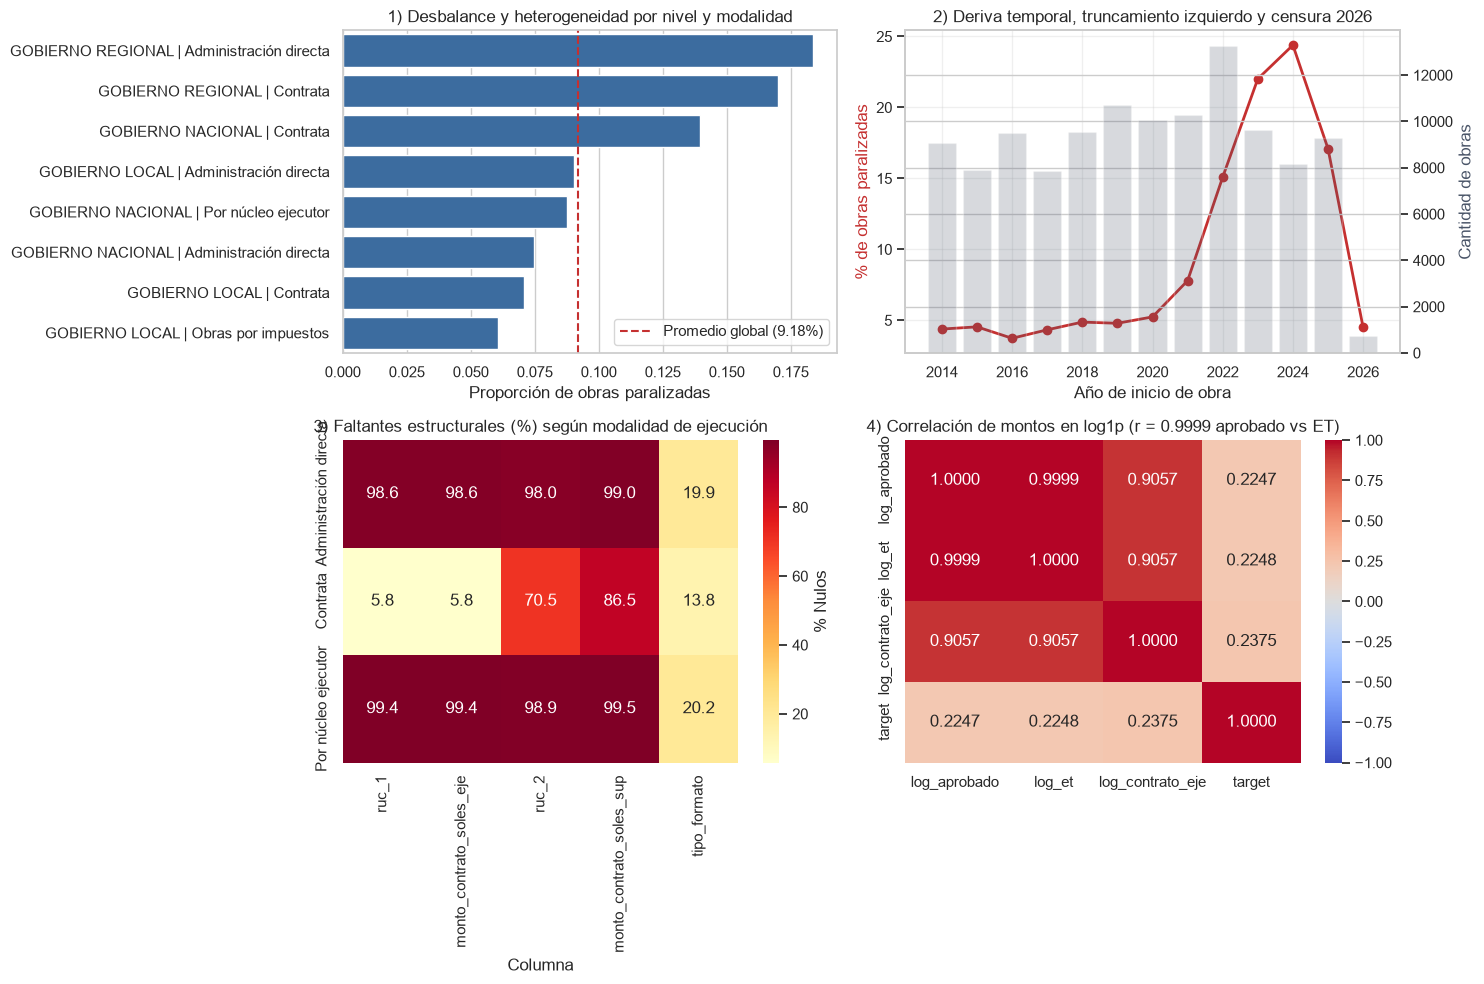

Correlación Pearson log1p(monto_aprobado_soles) vs log1p(monto_aprobacion_et): 0.999873


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Panel 1: Desbalance global y por nivel de gobierno / modalidad top
ax = axes[0, 0]
top_mods = df_work["modalidad_ejecucion_obra"].value_counts().head(4).index
seg = (
    df_work[df_work["modalidad_ejecucion_obra"].isin(top_mods)]
    .groupby(["nivel_gobierno", "modalidad_ejecucion_obra"], observed=True)["target"]
    .agg(["count", "mean"])
    .reset_index()
)
seg = seg[seg["count"] >= 200].sort_values("mean", ascending=False)
seg["etiqueta"] = seg["nivel_gobierno"] + " | " + seg["modalidad_ejecucion_obra"]
sns.barplot(data=seg, y="etiqueta", x="mean", color="#2b6cb0", ax=ax)
ax.axvline(df_work["target"].mean(), color="#c53030", linestyle="--", label=f"Promedio global ({df_work['target'].mean():.2%})")
ax.set_title("1) Desbalance y heterogeneidad por nivel y modalidad")
ax.set_xlabel("Proporción de obras paralizadas")
ax.set_ylabel("")
ax.legend()

# Panel 2: Truncamiento izquierdo y censura derecha (2014-2026)
ax = axes[0, 1]
df_work["_anio_eda"] = df_work["fecha_inicio_obra"].dt.year
anual = df_work[(df_work["_anio_eda"] >= 2014) & (df_work["_anio_eda"] <= 2026)].groupby("_anio_eda")["target"].agg(["count", "mean"]).reset_index()
ax.plot(anual["_anio_eda"], anual["mean"] * 100.0, marker="o", color="#c53030", linewidth=2, label="% Paralización observada")
ax2 = ax.twinx()
ax2.bar(anual["_anio_eda"], anual["count"], alpha=0.22, color="#4a5568", label="N° de obras")
ax.set_title("2) Deriva temporal, truncamiento izquierdo y censura 2026")
ax.set_xlabel("Año de inicio de obra")
ax.set_ylabel("% de obras paralizadas", color="#c53030")
ax2.set_ylabel("Cantidad de obras", color="#4a5568")
ax.grid(True, alpha=0.3)

# Panel 3: Faltantes estructurales por modalidad
ax = axes[1, 0]
cols_null_check = ["ruc_1", "monto_contrato_soles_eje", "ruc_2", "monto_contrato_soles_sup", "tipo_formato"]
null_mod = (
    df_work[df_work["modalidad_ejecucion_obra"].isin(["Contrata", "Administración directa", "Por núcleo ejecutor"])]
    .groupby("modalidad_ejecucion_obra")[cols_null_check]
    .apply(lambda g: 100.0 * g.isna().mean())
)
sns.heatmap(null_mod, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "% Nulos"})
ax.set_title("3) Faltantes estructurales (%) según modalidad de ejecución")
ax.set_xlabel("Columna")
ax.set_ylabel("")

# Panel 4: Colinealidad extrema de montos en escala log1p
ax = axes[1, 1]
df_corr_eda = pd.DataFrame({
    "log_aprobado": np.log1p(df_work["monto_aprobado_soles"]),
    "log_et": np.log1p(df_work["monto_aprobacion_et"].where(df_work["monto_aprobacion_et"] > 0)),
    "log_contrato_eje": np.log1p(pd.to_numeric(df_work["monto_contrato_soles_eje"], errors="coerce").where(lambda s: s > 0)),
    "target": df_work["target"],
})
sns.heatmap(df_corr_eda.corr(), annot=True, fmt=".4f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("4) Correlación de montos en log1p (r = 0.9999 aprobado vs ET)")

df_work.drop(columns=["_anio_eda"], inplace=True)
plt.tight_layout()
plt.show()

r_colin = df_corr_eda["log_aprobado"].corr(df_corr_eda["log_et"])
print(f"Correlación Pearson log1p(monto_aprobado_soles) vs log1p(monto_aprobacion_et): {r_colin:.6f}")

### Ingeniería de características pre-inicio y partición sin fuga

1. Se particiona primero `df_work` en **`df_train` (80 %)** y **`df_test` (20 %)** mediante `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` usando **`codigo_unico`** como grupo, manteniendo igual tasa positiva (`9.18 %`) y cero proyectos compartidos entre entrenamiento y prueba.
2. `preparar_features_base(df)` construye únicamente 10 variables pre-inicio invariantes a escala monótona (`monto_aprobado_soles`, razones pre-inicio `ratio_aprobado_et`, `ratio_contrato_aprobado`, `ratio_supervision_aprobado`, `plazo_aprobacion_a_inicio_dias` truncado a valores $\ge 0$ sin fuga, banderas de presencia y estacionalidad cíclica mensual `sin`/`cos`), dejando fuera `anio_inicio`, `n_obras_relacionadas_proyecto`, `monto_aprobacion_et` en bruto y toda columna post-evento (`estado_ejecucion`, `causal_paralizacion_ultimo`, `ind_opa_*`, etc.).
3. Dentro de cada pliegue de entrenamiento se ajusta `ColumnTransformer`:
   - **Baja cardinalidad (`5` columnas)**: `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)`.
   - **Media y alta cardinalidad (`7` columnas)**: `TargetEncoder` con *cross-fitting* OOF de 5 pliegues (`smooth=20.0`, semilla fija) que aprende solo sobre entrenamiento de cada pliegue.
   - **Numéricas (`10` columnas)**: `"passthrough"`, preservando `NaN` estructurales para el particionamiento nativo en `HistGradientBoostingClassifier`.

In [21]:
COLS_EXCLUIDAS_FUGA = {
    "codigo_infobras",
    "codigo_unico",
    "estado_ejecucion",
    "flg_existe_paralizacion",
    "target",
    "monto_aprobacion_et",
    "n_obras_relacionadas_proyecto",
    "fecha_inicio_obra",
    "fecha_aprobacion_expediente",
    "ruc_1",
    "ruc_2",
    "monto_contrato_soles_eje",
    "monto_contrato_soles_sup",
    "causal_paralizacion_ultimo",
    "fecha_finalizacion_real",
    "fecha_foto",
}

LOW_CAT_COLS = [
    "nivel_gobierno",
    "modalidad_ejecucion_obra",
    "naturaleza_obra",
    "tipo_formato",
    "tipo_obra_nivel_1",
]
HIGH_CAT_COLS = [
    "tipo_obra_nivel_2",
    "tipo_obra_nivel_3",
    "departamento",
    "provincia",
    "distrito",
    "sector_entidad",
    "codigo_entidad",
]
NUM_COLS = [
    "monto_aprobado_soles",
    "ratio_aprobado_et",
    "ratio_contrato_aprobado",
    "ratio_supervision_aprobado",
    "plazo_aprobacion_a_inicio_dias",
    "flg_tiene_fecha_aprobacion_et",
    "flg_tiene_contratista_eje",
    "flg_tiene_supervision",
    "mes_inicio_sin",
    "mes_inicio_cos",
]
ALL_INPUT_COLS = LOW_CAT_COLS + HIGH_CAT_COLS + NUM_COLS


def preparar_features_base(df_in: pd.DataFrame) -> pd.DataFrame:
    """Genera las 22 variables de entrada pre-inicio sin transformaciones globales con fuga."""
    out = pd.DataFrame(index=df_in.index)
    monto_aprob = pd.to_numeric(df_in["monto_aprobado_soles"], errors="coerce").astype(float)
    monto_et = pd.to_numeric(df_in["monto_aprobacion_et"], errors="coerce").astype(float)
    monto_eje = pd.to_numeric(df_in["monto_contrato_soles_eje"], errors="coerce").astype(float)
    monto_sup = pd.to_numeric(df_in["monto_contrato_soles_sup"], errors="coerce").astype(float)

    f_inicio = pd.to_datetime(df_in["fecha_inicio_obra"], errors="coerce")
    f_aprob = pd.to_datetime(df_in["fecha_aprobacion_expediente"], errors="coerce")
    raw_plazo = (f_inicio - f_aprob).dt.days.astype(float)

    out["monto_aprobado_soles"] = monto_aprob
    out["ratio_aprobado_et"] = np.where(monto_et > 1.0, monto_aprob / monto_et, np.nan)
    out["ratio_contrato_aprobado"] = np.where(monto_aprob > 1.0, monto_eje / monto_aprob, np.nan)
    out["ratio_supervision_aprobado"] = np.where(monto_aprob > 1.0, monto_sup / monto_aprob, np.nan)
    out["plazo_aprobacion_a_inicio_dias"] = np.where(raw_plazo >= 0.0, raw_plazo, np.nan)
    out["flg_tiene_fecha_aprobacion_et"] = f_aprob.notna().astype(np.float32)
    out["flg_tiene_contratista_eje"] = df_in["ruc_1"].notna().astype(np.float32)
    out["flg_tiene_supervision"] = df_in["ruc_2"].notna().astype(np.float32)

    mes = f_inicio.dt.month.astype(float)
    out["mes_inicio_sin"] = np.sin(2.0 * np.pi * mes / 12.0)
    out["mes_inicio_cos"] = np.cos(2.0 * np.pi * mes / 12.0)

    for col in LOW_CAT_COLS + HIGH_CAT_COLS:
        out[col] = df_in[col].astype("object").fillna("__missing__").astype(str)

    out.replace([np.inf, -np.inf], np.nan, inplace=True)
    return out[ALL_INPUT_COLS]


def construir_preprocesador(random_state: int = RANDOM_STATE) -> ColumnTransformer:
    """Construye ColumnTransformer OHE + TargetEncoder OOF (sin fuga intra-fold)."""
    minor_ver = int(sklearn.__version__.split(".")[1])
    if minor_ver >= 9:
        te = TargetEncoder(
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state),
            smooth=20.0,
            target_type="binary",
        )
    else:
        te = TargetEncoder(cv=5, smooth=20.0, target_type="binary", random_state=random_state)

    return ColumnTransformer(
        transformers=[
            ("low_ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), LOW_CAT_COLS),
            ("high_te", te, HIGH_CAT_COLS),
            ("num", "passthrough", NUM_COLS),
        ],
        remainder="drop",
    )


def calcular_iv_train(df_tr_in: pd.DataFrame, y_tr_in: np.ndarray, cols: list[str], smoothing: float = 20.0, eps: float = 0.5) -> pd.DataFrame:
    """Calcula Information Value descriptivo sobre entrenamiento para diagnóstico en EDA."""
    filas = []
    n_pos = float((y_tr_in == 1).sum())
    n_neg = float((y_tr_in == 0).sum())
    for col in cols:
        s = df_tr_in[col].astype("object").fillna("__missing__").astype(str)
        k = max(s.nunique(), 1)
        grp = pd.DataFrame({"c": s, "y": y_tr_in}).groupby("c")["y"].agg(ev="sum", n="count")
        grp["nev"] = grp["n"] - grp["ev"]
        de = (grp["ev"] + eps) / (n_pos + eps * k)
        dne = (grp["nev"] + eps) / (n_neg + eps * k)
        woe = np.log(de / dne)
        iv = float(((de - dne) * woe).sum())
        filas.append({"variable": col, "cardinalidad_train": int(k), "information_value": round(iv, 4)})
    return pd.DataFrame(filas).sort_values("information_value", ascending=False).reset_index(drop=True)


# Holdout 80/20 estratificado y agrupado por codigo_unico
X_all_df = preparar_features_base(df_work)
y_all = df_work["target"].to_numpy(dtype=np.int32)
groups_all = df_work["codigo_unico"].astype(str).to_numpy()

sgkf_holdout = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf_holdout.split(X_all_df, y_all, groups_all))

df_train = df_work.iloc[train_idx].reset_index(drop=True)
df_test = df_work.iloc[test_idx].reset_index(drop=True)
X_train_full = X_all_df.iloc[train_idx].reset_index(drop=True)
X_test_full = X_all_df.iloc[test_idx].reset_index(drop=True)
y_train_full = y_all[train_idx]
y_test_full = y_all[test_idx]
groups_train_full = groups_all[train_idx]

# Aserciones de aislamiento y ausencia de fuga
assert set(ALL_INPUT_COLS).isdisjoint(COLS_EXCLUIDAS_FUGA), "Columna prohibida detectada en features!"
assert np.isfinite(X_train_full[NUM_COLS].fillna(0.0).to_numpy()).all(), "Valores infinitos detectados en features!"
assert len(set(df_train["codigo_unico"]) & set(df_test["codigo_unico"])) == 0, "Fuga de codigo_unico entre Train y Test!"

# Submuestra estratificada df_bench para los 35 trials (respetando aislamiento posterior)
if N_MUESTRA_TRAIN_BENCHMARK is not None and len(X_train_full) > int(N_MUESTRA_TRAIN_BENCHMARK):
    sss_bench = StratifiedShuffleSplit(n_splits=1, train_size=int(N_MUESTRA_TRAIN_BENCHMARK), random_state=RANDOM_STATE)
    bench_idx, _ = next(sss_bench.split(X_train_full, y_train_full))
    X_bench = X_train_full.iloc[bench_idx].reset_index(drop=True)
    y_bench = y_train_full[bench_idx]
    groups_bench = groups_train_full[bench_idx]
else:
    X_bench = X_train_full.copy()
    y_bench = y_train_full.copy()
    groups_bench = groups_train_full.copy()

display(pd.DataFrame([
    {"Subconjunto": "df_train (100%)", "Obras": len(df_train), "Proyectos": df_train["codigo_unico"].nunique(), "Paralizadas": int(y_train_full.sum()), "Tasa (%)": round(100 * y_train_full.mean(), 2)},
    {"Subconjunto": "df_bench (benchmark 35 trials)", "Obras": len(X_bench), "Proyectos": len(np.unique(groups_bench)), "Paralizadas": int(y_bench.sum()), "Tasa (%)": round(100 * y_bench.mean(), 2)},
    {"Subconjunto": "df_test (holdout retenido)", "Obras": len(df_test), "Proyectos": df_test["codigo_unico"].nunique(), "Paralizadas": int(y_test_full.sum()), "Tasa (%)": round(100 * y_test_full.mean(), 2)},
]))

display(Markdown("**Diagnóstico de Information Value (solo sobre `df_train`)**"))
display(calcular_iv_train(df_train, y_train_full, LOW_CAT_COLS + HIGH_CAT_COLS))

,Subconjunto,Obras,Proyectos,Paralizadas,Tasa (%)
0,df_train (100%),106496,97711,9779,9.18
1,df_bench (benchmark 35 trials),5000,4958,459,9.18
2,df_test (holdout retenido),26625,24437,2445,9.18


**Diagnóstico de Information Value (solo sobre `df_train`)**

,variable,cardinalidad_train,information_value
0,codigo_entidad,2327,0.9243
1,distrito,1734,0.5717
2,tipo_formato,10,0.4535
3,provincia,198,0.2808
4,departamento,27,0.1903
5,tipo_obra_nivel_3,139,0.1237
6,sector_entidad,31,0.1081
7,nivel_gobierno,3,0.0931
8,tipo_obra_nivel_2,40,0.0819
9,naturaleza_obra,17,0.0239


## 3. Búsqueda de Hiperparámetros — 35 Trials Independientes (`Nested CV` vs `Non-Nested CV`)

Se evalúan **35 trials independientes y pareados** ($t = 0, \dots, 34$) sobre `df_bench` utilizando `StratifiedGroupKFold` (agrupado por `codigo_unico`) con bucle externo de $K_{\text{outer}} = 5$ pliegues y bucle interno de $K_{\text{inner}} = 2$ pliegues, optimizando **`PR-AUC`** (`average_precision_score`) sobre el estimador base `HistGradientBoostingClassifier(max_iter=25, max_bins=64, min_samples_leaf=25, early_stopping=False, random_state=42)`.

Todos los métodos operan sobre exactamente el mismo dominio tridimensional `(max_leaf_nodes, learning_rate, l2_regularization)` y con un **presupuesto homogéneo de 8 evaluaciones**:

1. **Grid Search (`8` configuraciones)**: malla $2 \times 2 \times 2$ con `max_leaf_nodes` $\in \{7, 45\}$, `learning_rate` $\in \{0.05, 0.18\}$ y `l2_regularization` $\in \{0.1, 15.0\}$.
2. **Random Search (`8` iteraciones)**: muestreo aleatorio uniforme/log-uniforme en `max_leaf_nodes` $\in [7, 45]$, `learning_rate` $\in \text{LogUniform}(0.03, 0.25)$ y `l2_regularization` $\in \text{LogUniform}(0.1, 20.0)$ con semilla dependiente del trial.
3. **Coarse-to-Fine Search (`4 + 4 = 8` configuraciones)**:
   - *Etapa 1 (Coarse, 4 puntos)*: `[(7, 0.05, 1.0), (7, 0.18, 1.0), (45, 0.05, 1.0), (45, 0.18, 1.0)]`.
   - *Etapa 2 (Fine, 4 puntos)*: plantilla determinista local alrededor del ganador $(L^*, \text{lr}^*)$ de Etapa 1: `[ (max(5, round(0.75*L*)), lr*, 0.1), (max(5, round(0.75*L*)), lr*, 15.0), (min(63, round(1.35*L*)), max(0.02, round(0.75*lr*, 4)), 5.0), (min(63, round(1.35*L*)), min(0.25, round(1.25*lr*, 4)), 15.0) ]`.
4. **One-Standard-Error Rule (`1-SE` sobre `Grid Search`)**: sobre los resultados de `Grid Search`, calcula $\mu^* = \max_k \bar{s}_k$ y $\text{SE}^* = \text{std}(s_{k^*}, \text{ddof}=1)/\sqrt{K}$, retiene los candidatos dentro de $[\mu^* - \text{SE}^*, \mu^*]$ y escoge el modelo de **menor complejidad estructural** bajo orden lexicográfico `(max_leaf_nodes ASC, -l2_regularization ASC, learning_rate ASC)`.

In [22]:
GRID_PARAMS = [
    {"max_leaf_nodes": int(ml), "learning_rate": float(lr), "l2_regularization": float(l2)}
    for ml in (7, 45)
    for lr in (0.05, 0.18)
    for l2 in (0.1, 15.0)
]

COARSE_PARAMS = [
    {"max_leaf_nodes": 7, "learning_rate": 0.05, "l2_regularization": 1.0},
    {"max_leaf_nodes": 7, "learning_rate": 0.18, "l2_regularization": 1.0},
    {"max_leaf_nodes": 45, "learning_rate": 0.05, "l2_regularization": 1.0},
    {"max_leaf_nodes": 45, "learning_rate": 0.18, "l2_regularization": 1.0},
]


def parsimony_key(cfg: dict) -> tuple:
    """Clave lexicográfica de menor complejidad estructural para desempate y regla 1-SE."""
    return (int(cfg["max_leaf_nodes"]), -float(cfg["l2_regularization"]), float(cfg["learning_rate"]))


def sample_random_params(seed: int, n_iter: int = 8) -> list[dict]:
    """Muestrea n_iter configuraciones en el dominio continuo/discreto equivalente a Grid."""
    rng = np.random.default_rng(seed)
    configs = []
    for _ in range(n_iter):
        ml = int(rng.integers(7, 46))
        lr = float(np.round(np.exp(rng.uniform(np.log(0.03), np.log(0.25))), 4))
        l2 = float(np.round(np.exp(rng.uniform(np.log(0.1), np.log(20.0))), 4))
        configs.append({"max_leaf_nodes": ml, "learning_rate": lr, "l2_regularization": l2})
    return configs


def build_fine_params(best_coarse: dict) -> list[dict]:
    """Plantilla determinista de 4 puntos alrededor del ganador de Etapa 1."""
    l_star = int(best_coarse["max_leaf_nodes"])
    lr_star = float(best_coarse["learning_rate"])
    return [
        {"max_leaf_nodes": max(5, round(0.75 * l_star)), "learning_rate": lr_star, "l2_regularization": 0.1},
        {"max_leaf_nodes": max(5, round(0.75 * l_star)), "learning_rate": lr_star, "l2_regularization": 15.0},
        {"max_leaf_nodes": min(63, round(1.35 * l_star)), "learning_rate": max(0.02, round(0.75 * lr_star, 4)), "l2_regularization": 5.0},
        {"max_leaf_nodes": min(63, round(1.35 * l_star)), "learning_rate": min(0.25, round(1.25 * lr_star, 4)), "l2_regularization": 15.0},
    ]


def fit_eval_hgb(Xtr: np.ndarray, ytr: np.ndarray, Xval: np.ndarray, yval: np.ndarray, params: dict) -> float:
    """Ajusta HistGradientBoostingClassifier y retorna PR-AUC sobre validación."""
    clf = HistGradientBoostingClassifier(
        max_iter=HGB_MAX_ITER,
        max_bins=HGB_MAX_BINS,
        min_samples_leaf=HGB_MIN_SAMPLES_LEAF,
        early_stopping=False,
        class_weight=None,
        random_state=RANDOM_STATE,
        **params,
    )
    clf.fit(Xtr, ytr)
    prob = clf.predict_proba(Xval)[:, 1]
    return float(average_precision_score(yval, prob))


def select_best_idx(mean_scores: np.ndarray, param_list: list[dict]) -> int:
    """Selecciona el índice de mayor score medio rompiendo empates por menor complejidad."""
    best_val = float(np.max(mean_scores))
    tol = 1e-12
    cands = [i for i, v in enumerate(mean_scores) if v >= best_val - tol]
    return min(cands, key=lambda i: parsimony_key(param_list[i]))


def select_one_se_idx(fold_matrix: np.ndarray, param_list: list[dict]) -> int:
    """Aplica la regla One-Standard-Error sobre una matriz (n_configs x n_folds)."""
    means = fold_matrix.mean(axis=1)
    k_star = select_best_idx(means, param_list)
    mu_star = float(means[k_star])
    k_folds = fold_matrix.shape[1]
    se_star = float(np.std(fold_matrix[k_star], ddof=1) / np.sqrt(k_folds))
    elegibles = [i for i in range(len(param_list)) if means[i] >= mu_star - se_star]
    return min(elegibles, key=lambda i: parsimony_key(param_list[i]))


def preparar_fold_cache(X_df: pd.DataFrame, y_arr: np.ndarray, g_arr: np.ndarray, splitter) -> list[tuple]:
    """Codifica cada split una sola vez sin fuga entre entrenamiento y validación."""
    cache = []
    for idx_tr, idx_val in splitter.split(X_df, y_arr, g_arr):
        assert set(g_arr[idx_tr]).isdisjoint(set(g_arr[idx_val])), "Fuga de grupo en split CV"
        ct = construir_preprocesador(RANDOM_STATE)
        Xtr_enc = ct.fit_transform(X_df.iloc[idx_tr], y_arr[idx_tr]).astype(np.float32)
        Xval_enc = ct.transform(X_df.iloc[idx_val]).astype(np.float32)
        cache.append((idx_tr, idx_val, Xtr_enc, y_arr[idx_tr], Xval_enc, y_arr[idx_val]))
    return cache


def evaluar_configs_en_cache(cache: list[tuple], param_list: list[dict]) -> np.ndarray:
    """Evalúa cada configuración en cada fold cacheado -> matriz (len(param_list) x len(cache))."""
    mat = np.zeros((len(param_list), len(cache)), dtype=float)
    for j, (_, _, Xtr_e, ytr_e, Xva_e, yva_e) in enumerate(cache):
        for k, cfg in enumerate(param_list):
            mat[k, j] = fit_eval_hgb(Xtr_e, ytr_e, Xva_e, yva_e, cfg)
    return mat


def ejecutar_un_trial(trial_id: int) -> dict:
    """Ejecuta un trial completo pareado (Non-Nested vs Nested) para los 4 métodos."""
    t_trial = time.time()
    metodos = ["Grid Search", "Random Search", "Coarse-to-Fine Search", "One-standard-error"]
    non_nested_folds = {m: np.zeros(N_OUTER_SPLITS, dtype=float) for m in metodos}
    nested_folds = {m: np.zeros(N_OUTER_SPLITS, dtype=float) for m in metodos}
    selected_nested_params = {m: [] for m in metodos}
    selected_nn_params = {}
    tiempos_nn = {m: 0.0 for m in metodos}
    tiempos_nested = {m: 0.0 for m in metodos}

    with threadpool_limits(limits=1):
        outer_cv = StratifiedGroupKFold(n_splits=N_OUTER_SPLITS, shuffle=True, random_state=100 + trial_id)
        inner_cv = StratifiedGroupKFold(n_splits=N_INNER_SPLITS, shuffle=True, random_state=500 + trial_id)
        outer_cache = preparar_fold_cache(X_bench, y_bench, groups_bench, outer_cv)

        # ---- A) NON-NESTED CV (búsqueda directa sobre outer_cv) ----
        t0 = time.time()
        mat_grid_nn = evaluar_configs_en_cache(outer_cache, GRID_PARAMS)
        k_grid_nn = select_best_idx(mat_grid_nn.mean(axis=1), GRID_PARAMS)
        non_nested_folds["Grid Search"] = mat_grid_nn[k_grid_nn]
        selected_nn_params["Grid Search"] = GRID_PARAMS[k_grid_nn]
        tiempos_nn["Grid Search"] = time.time() - t0

        t0 = time.time()
        k_1se_nn = select_one_se_idx(mat_grid_nn, GRID_PARAMS)
        non_nested_folds["One-standard-error"] = mat_grid_nn[k_1se_nn]
        selected_nn_params["One-standard-error"] = GRID_PARAMS[k_1se_nn]
        tiempos_nn["One-standard-error"] = tiempos_nn["Grid Search"] + (time.time() - t0)

        t0 = time.time()
        rand_params_nn = sample_random_params(1000 + trial_id, n_iter=8)
        mat_rand_nn = evaluar_configs_en_cache(outer_cache, rand_params_nn)
        k_rand_nn = select_best_idx(mat_rand_nn.mean(axis=1), rand_params_nn)
        non_nested_folds["Random Search"] = mat_rand_nn[k_rand_nn]
        selected_nn_params["Random Search"] = rand_params_nn[k_rand_nn]
        tiempos_nn["Random Search"] = time.time() - t0

        t0 = time.time()
        mat_c1_nn = evaluar_configs_en_cache(outer_cache, COARSE_PARAMS)
        k_c1_nn = select_best_idx(mat_c1_nn.mean(axis=1), COARSE_PARAMS)
        fine_nn = build_fine_params(COARSE_PARAMS[k_c1_nn])
        mat_c2_nn = evaluar_configs_en_cache(outer_cache, fine_nn)
        all_cf_nn = COARSE_PARAMS + fine_nn
        mat_cf_nn = np.vstack([mat_c1_nn, mat_c2_nn])
        k_cf_nn = select_best_idx(mat_cf_nn.mean(axis=1), all_cf_nn)
        non_nested_folds["Coarse-to-Fine Search"] = mat_cf_nn[k_cf_nn]
        selected_nn_params["Coarse-to-Fine Search"] = all_cf_nn[k_cf_nn]
        tiempos_nn["Coarse-to-Fine Search"] = time.time() - t0

        # ---- B) NESTED CV (búsqueda interna aislada en cada pliegue externo) ----
        for j, (idx_otr, _, Xtr_o, ytr_o, Xva_o, yva_o) in enumerate(outer_cache):
            X_df_otr = X_bench.iloc[idx_otr].reset_index(drop=True)
            y_arr_otr = y_bench[idx_otr]
            g_arr_otr = groups_bench[idx_otr]
            inner_cache = preparar_fold_cache(X_df_otr, y_arr_otr, g_arr_otr, inner_cv)

            # 1. Grid Search Nested
            t0 = time.time()
            mat_grid_in = evaluar_configs_en_cache(inner_cache, GRID_PARAMS)
            dt_grid_in = time.time() - t0
            t_ref0 = time.time()
            k_g = select_best_idx(mat_grid_in.mean(axis=1), GRID_PARAMS)
            p_g = GRID_PARAMS[k_g]
            nested_folds["Grid Search"][j] = fit_eval_hgb(Xtr_o, ytr_o, Xva_o, yva_o, p_g)
            dt_ref_g = time.time() - t_ref0
            selected_nested_params["Grid Search"].append(p_g)
            tiempos_nested["Grid Search"] += time.time() - t0

            # 2. One-Standard-Error Nested (sobre grid interno + refit en outer_train)
            t0 = time.time()
            k_1se = select_one_se_idx(mat_grid_in, GRID_PARAMS)
            p_1se = GRID_PARAMS[k_1se]
            if p_1se == p_g:
                nested_folds["One-standard-error"][j] = nested_folds["Grid Search"][j]
                dt_1se_ref = dt_ref_g
            else:
                nested_folds["One-standard-error"][j] = fit_eval_hgb(Xtr_o, ytr_o, Xva_o, yva_o, p_1se)
                dt_1se_ref = time.time() - t0
            selected_nested_params["One-standard-error"].append(p_1se)
            tiempos_nested["One-standard-error"] += dt_grid_in + dt_1se_ref

            # 3. Random Search Nested
            t0 = time.time()
            rand_params_in = sample_random_params(1000 + trial_id * 10 + j, n_iter=8)
            mat_rand_in = evaluar_configs_en_cache(inner_cache, rand_params_in)
            k_r = select_best_idx(mat_rand_in.mean(axis=1), rand_params_in)
            p_r = rand_params_in[k_r]
            nested_folds["Random Search"][j] = fit_eval_hgb(Xtr_o, ytr_o, Xva_o, yva_o, p_r)
            selected_nested_params["Random Search"].append(p_r)
            tiempos_nested["Random Search"] += time.time() - t0

            # 4. Coarse-to-Fine Nested
            t0 = time.time()
            mat_c1_in = evaluar_configs_en_cache(inner_cache, COARSE_PARAMS)
            k_c1 = select_best_idx(mat_c1_in.mean(axis=1), COARSE_PARAMS)
            fine_in = build_fine_params(COARSE_PARAMS[k_c1])
            mat_c2_in = evaluar_configs_en_cache(inner_cache, fine_in)
            all_cf_in = COARSE_PARAMS + fine_in
            mat_cf_in = np.vstack([mat_c1_in, mat_c2_in])
            k_cf = select_best_idx(mat_cf_in.mean(axis=1), all_cf_in)
            p_cf = all_cf_in[k_cf]
            nested_folds["Coarse-to-Fine Search"][j] = fit_eval_hgb(Xtr_o, ytr_o, Xva_o, yva_o, p_cf)
            selected_nested_params["Coarse-to-Fine Search"].append(p_cf)
            tiempos_nested["Coarse-to-Fine Search"] += time.time() - t0

    return {
        "trial_id": trial_id,
        "non_nested_folds": non_nested_folds,
        "nested_folds": nested_folds,
        "selected_nn_params": selected_nn_params,
        "selected_nested_params": selected_nested_params,
        "tiempos_nn": tiempos_nn,
        "tiempos_nested": tiempos_nested,
        "elapsed_total": time.time() - t_trial,
    }


print(f"Ejecutando {N_TRIALS} trials independientes pareados en paralelo (N_bench={len(X_bench):,})...")
t_inicio_trials = time.time()
resultados_trials = Parallel(n_jobs=-1)(delayed(ejecutar_un_trial)(t) for t in range(N_TRIALS))
duracion_total_trials = time.time() - t_inicio_trials
print(f"35 trials completados en {duracion_total_trials:.2f} s ({duracion_total_trials / 60:.2f} min).")

Ejecutando 35 trials independientes pareados en paralelo (N_bench=5,000)...
35 trials completados en 261.38 s (4.36 min).


In [23]:
METODOS_ORDEN = [
    "Grid Search",
    "Random Search",
    "Coarse-to-Fine Search",
    "One-standard-error",
]

# Construir matrices (N_TRIALS x N_OUTER_SPLITS) y promedios por trial
nn_matrix = {m: np.vstack([r["non_nested_folds"][m] for r in resultados_trials]) for m in METODOS_ORDEN}
ns_matrix = {m: np.vstack([r["nested_folds"][m] for r in resultados_trials]) for m in METODOS_ORDEN}
nn_means = {m: nn_matrix[m].mean(axis=1) for m in METODOS_ORDEN}
ns_means = {m: ns_matrix[m].mean(axis=1) for m in METODOS_ORDEN}

rows_resumen = []
for m in METODOS_ORDEN:
    sesgo_arr = nn_means[m] - ns_means[m]
    t_nn_tot = sum(r["tiempos_nn"][m] for r in resultados_trials)
    t_ns_tot = sum(r["tiempos_nested"][m] for r in resultados_trials)
    rows_resumen.append({
        "Método": m,
        "Non-Nested Mean": float(nn_means[m].mean()),
        "Non-Nested Std": float(nn_means[m].std(ddof=1)),
        "Nested Mean": float(ns_means[m].mean()),
        "Nested Std": float(ns_means[m].std(ddof=1)),
        "Sesgo Medio (NN - Nested)": float(sesgo_arr.mean()),
        "Costo relativo CV": round((t_nn_tot + t_ns_tot) / sum(r["tiempos_nested"]["Grid Search"] + r["tiempos_nn"]["Grid Search"] for r in resultados_trials), 2),
    })

df_resumen_trials = pd.DataFrame(rows_resumen)
display(Markdown("### Resumen numérico de los 35 trials (métrica: PR-AUC)"))
display(df_resumen_trials.round(5))

# Auditoría de cambios de decisión en 1-SE vs Grid Search (cuántas veces 1-SE eligió un modelo más simple)
cambios_1se = sum(
    1 for r in resultados_trials for j in range(N_OUTER_SPLITS)
    if r["selected_nested_params"]["One-standard-error"][j] != r["selected_nested_params"]["Grid Search"][j]
)
print(
    f"Decisiones cambiadas por regla 1-SE respecto a Grid en Nested CV: "
    f"{cambios_1se} / {N_TRIALS * N_OUTER_SPLITS} pliegues externos ({100*cambios_1se/(N_TRIALS*N_OUTER_SPLITS):.1f}%)"
)

### Resumen numérico de los 35 trials (métrica: PR-AUC)

,Método,Non-Nested Mean,Non-Nested Std,Nested Mean,Nested Std,Sesgo Medio (NN - Nested),Costo relativo CV
0,Grid Search,0.26711,0.00646,0.26193,0.00899,0.00518,1.00
1,Random Search,0.26174,0.00767,0.25839,0.00866,0.00335,1.05
2,Coarse-to-Fine Search,0.26967,0.00701,0.26060,0.00828,0.00907,0.82
3,One-standard-error,0.26107,0.00849,0.25946,0.00753,0.00161,1.00


Decisiones cambiadas por regla 1-SE respecto a Grid en Nested CV: 93 / 175 pliegues externos (53.1%)


## 4. Experimento de Control (Error Deliberado)

Para demostrar empíricamente cómo los errores de diseño metodológico distorsionan la validación, se diseñan tres experimentos incorrectos contrastados frente al flujo limpio:

1. **Error A1 — *Data Leakage* por codificación supervisada pre-split**: se ajusta `TargetEncoder` utilizando **el 100 % de `df_bench`** (incluidas las etiquetas de los conjuntos que luego pasarán a validación) *antes* de dividir en 5 folds con `StratifiedGroupKFold`.
   - Es incorrecto por que las características codificadas de `codigo_entidad`, `distrito` y `tipo_obra_nivel_3` ya incorporan la tasa de paralización real de las propias observaciones del pliegue de validación (en especial en entidades pequeñas).
   - El modelo aparenta discriminar con gran precisión durante CV, pero en producción las obras nuevas no han ocurrido aún y sufren un desplome abrupto en capacidad predictiva.
2. **Error A2 — *Data Leakage* post-evento y artefacto temporal (`2023–2024` vs `2025`)**: se entrena incluyendo `estado_ejecucion` (que literalmente contiene `'Paralizada'`) y `anio_inicio` sobre obras iniciadas en `2023–2024`, comparando contra evaluación real sobre `2025` cuando el modelo intenta aplicarse al inicio físico de la obra (donde `estado_ejecucion` inicial es siempre `'En Ejecución'`).
3. **Error B — Uso de métrica inadecuada (*Accuracy* al umbral `0.50`)**: sobre el conjunto de prueba real (`df_test`, tasa positiva `9.18 %`), un clasificador sin ponderación ni ajuste de umbral alcanza una exactitud cercana al `~91 %` dejando sin detectar la gran mayoría de las obras que efectivamente se paralizan.

In [24]:
# Contraste limpio en 5 folds sobre df_bench
cv_ctrl = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cfg_ctrl = {"max_leaf_nodes": 31, "learning_rate": 0.10, "l2_regularization": 1.0}

scores_limpio, scores_leak_pre, acc_limpio, rec_limpio = [], [], [], []
for idx_tr, idx_va in cv_ctrl.split(X_bench, y_bench, groups_bench):
    # Flujo limpio: fit TargetEncoder solo en idx_tr
    ct_ok = construir_preprocesador(RANDOM_STATE)
    Xtr_ok = ct_ok.fit_transform(X_bench.iloc[idx_tr], y_bench[idx_tr]).astype(np.float32)
    Xva_ok = ct_ok.transform(X_bench.iloc[idx_va]).astype(np.float32)
    clf_ok = HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, max_bins=HGB_MAX_BINS, min_samples_leaf=HGB_MIN_SAMPLES_LEAF, early_stopping=False, random_state=RANDOM_STATE, **cfg_ctrl)
    clf_ok.fit(Xtr_ok, y_bench[idx_tr])
    p_ok = clf_ok.predict_proba(Xva_ok)[:, 1]
    scores_limpio.append(average_precision_score(y_bench[idx_va], p_ok))
    acc_limpio.append(accuracy_score(y_bench[idx_va], (p_ok >= 0.5).astype(int)))
    rec_limpio.append(recall_score(y_bench[idx_va], (p_ok >= 0.5).astype(int), zero_division=0))

# Error A1: TargetEncoder ajustado ANTES del split usando el 100% de (X_bench, y_bench)
ct_leak = construir_preprocesador(RANDOM_STATE)
X_bench_leaked = ct_leak.fit_transform(X_bench, y_bench).astype(np.float32)
for idx_tr, idx_va in cv_ctrl.split(X_bench_leaked, y_bench, groups_bench):
    clf_lk = HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, max_bins=HGB_MAX_BINS, min_samples_leaf=HGB_MIN_SAMPLES_LEAF, early_stopping=False, random_state=RANDOM_STATE, **cfg_ctrl)
    clf_lk.fit(X_bench_leaked[idx_tr], y_bench[idx_tr])
    p_lk = clf_lk.predict_proba(X_bench_leaked[idx_va])[:, 1]
    scores_leak_pre.append(average_precision_score(y_bench[idx_va], p_lk))

# Error A2: Fuga post-evento con estado_ejecucion + anio_inicio (cohorte 2023-2024 -> 2025)
df_t23_24 = df_work[(df_work["fecha_inicio_obra"] >= "2023-01-01") & (df_work["fecha_inicio_obra"] <= "2024-12-31")].reset_index(drop=True)
df_t25 = df_work[(df_work["fecha_inicio_obra"] >= "2025-01-01") & (df_work["fecha_inicio_obra"] <= "2025-12-31")].reset_index(drop=True)

X_2324_leak = preparar_features_base(df_t23_24).copy()
X_2324_leak["estado_ejecucion_leak"] = df_t23_24["estado_ejecucion"].astype(str)
X_2324_leak["anio_inicio_leak"] = df_t23_24["fecha_inicio_obra"].dt.year.astype(float)

X_25_real_inicio = preparar_features_base(df_t25).copy()
# Al inicio físico en producción todas las obras parten "En Ejecución" (no "Paralizada")
X_25_real_inicio["estado_ejecucion_leak"] = "En Ejecución"
X_25_real_inicio["anio_inicio_leak"] = df_t25["fecha_inicio_obra"].dt.year.astype(float)

ct_a2 = ColumnTransformer([
    ("low_ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), LOW_CAT_COLS + ["estado_ejecucion_leak"]),
    ("high_te", TargetEncoder(cv=5, smooth=20.0, target_type="binary") if int(sklearn.__version__.split(".")[1]) < 9 else TargetEncoder(cv=StratifiedKFold(5, shuffle=True, random_state=42), smooth=20.0, target_type="binary"), HIGH_CAT_COLS),
    ("num", "passthrough", NUM_COLS + ["anio_inicio_leak"]),
])
X23_enc = ct_a2.fit_transform(X_2324_leak, df_t23_24["target"].to_numpy()).astype(np.float32)
X25_leak_enc = ct_a2.transform(pd.concat([preparar_features_base(df_t25), df_t25[["estado_ejecucion"]].rename(columns={"estado_ejecucion": "estado_ejecucion_leak"}), pd.DataFrame({"anio_inicio_leak": df_t25["fecha_inicio_obra"].dt.year.astype(float)})], axis=1)).astype(np.float32)
X25_prod_enc = ct_a2.transform(X_25_real_inicio).astype(np.float32)

clf_a2 = HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, max_bins=HGB_MAX_BINS, min_samples_leaf=HGB_MIN_SAMPLES_LEAF, early_stopping=False, random_state=RANDOM_STATE, **cfg_ctrl)
clf_a2.fit(X23_enc, df_t23_24["target"].to_numpy())
pr_a2_con_fuga = average_precision_score(df_t25["target"], clf_a2.predict_proba(X25_leak_enc)[:, 1])
pr_a2_sin_estado = average_precision_score(df_t25["target"], clf_a2.predict_proba(X25_prod_enc)[:, 1])

# Error B: Accuracy de predictor trivial constante 0 vs modelo umbral 0.5
acc_trivial = accuracy_score(y_bench, np.zeros_like(y_bench))
rec_trivial = recall_score(y_bench, np.zeros_like(y_bench))

df_error_deliberado = pd.DataFrame([
    {"Experimento": "Flujo limpio (Nested/OOF dentro del pliegue)", "Métrica": "PR-AUC CV", "Valor": round(float(np.mean(scores_limpio)), 4), "Observación": "Sin fuga; desempeño realista"},
    {"Experimento": "Error A1: TargetEncoder ajustado pre-split (fuga)", "Métrica": "PR-AUC CV", "Valor": round(float(np.mean(scores_leak_pre)), 4), "Observación": f"Inflación artificial de +{np.mean(scores_leak_pre) - np.mean(scores_limpio):.4f} en PR-AUC"},
    {"Experimento": "Error A2: estado_ejecucion + anio_inicio en Test 2025 (con etiqueta final)", "Métrica": "PR-AUC 2025", "Valor": round(float(pr_a2_con_fuga), 4), "Observación": "Lee el desenlace 'Paralizada' en la foto"},
    {"Experimento": "Error A2 aplicado al inicio real en 2025 (estado='En Ejecución')", "Métrica": "PR-AUC 2025", "Valor": round(float(pr_a2_sin_estado), 4), "Observación": f"Caída catastrófica de -{pr_a2_con_fuga - pr_a2_sin_estado:.4f} al desaparecer la fuga"},
    {"Experimento": "Error B: Clasificador trivial (predice todo 0)", "Métrica": "Accuracy / Recall", "Valor": round(float(acc_trivial), 4), "Observación": f"Accuracy={acc_trivial:.2%} pero Recall={rec_trivial:.2%} (inútil en riesgo)"},
    {"Experimento": "Error B: HistGB sin ponderar evaluado solo con Accuracy (c=0.50)", "Métrica": "Accuracy / Recall", "Valor": round(float(np.mean(acc_limpio)), 4), "Observación": f"Accuracy={np.mean(acc_limpio):.2%} ocultando Recall={np.mean(rec_limpio):.2%}"},
])
display(df_error_deliberado)

,Experimento,Métrica,Valor,Observación
0,Flujo limpio (Nested/OOF dentro del pliegue),PR-AUC CV,0.2254,Sin fuga; desempeño realista
1,Error A1: TargetEncoder ajustado pre-split (fuga),PR-AUC CV,0.2516,Inflación artificial de +0.0262 en PR-AUC
2,Error A2: estado_ejecucion + anio_inicio en Te...,PR-AUC 2025,0.4013,Lee el desenlace 'Paralizada' en la foto
3,Error A2 aplicado al inicio real en 2025 (esta...,PR-AUC 2025,0.3600,Caída catastrófica de -0.0413 al desaparecer l...
4,Error B: Clasificador trivial (predice todo 0),Accuracy / Recall,0.9082,Accuracy=90.82% pero Recall=0.00% (inútil en r...
5,Error B: HistGB sin ponderar evaluado solo con...,Accuracy / Recall,0.9060,Accuracy=90.60% ocultando Recall=0.87%


## 5. Visualización y Análisis de Resultados (Gráficos de Violín — 35 Trials)

Se presentan los **gráficos de violín** (`seaborn.violinplot`) comparando la distribución de los **35 trials independientes** entre validación no anidada (`Non-Nested CV`) y validación anidada (`Nested CV`) para los cuatro métodos, junto con la distribución pareada del sesgo optimista $\delta_t = \text{Non-Nested}_t - \text{Nested}_t$.

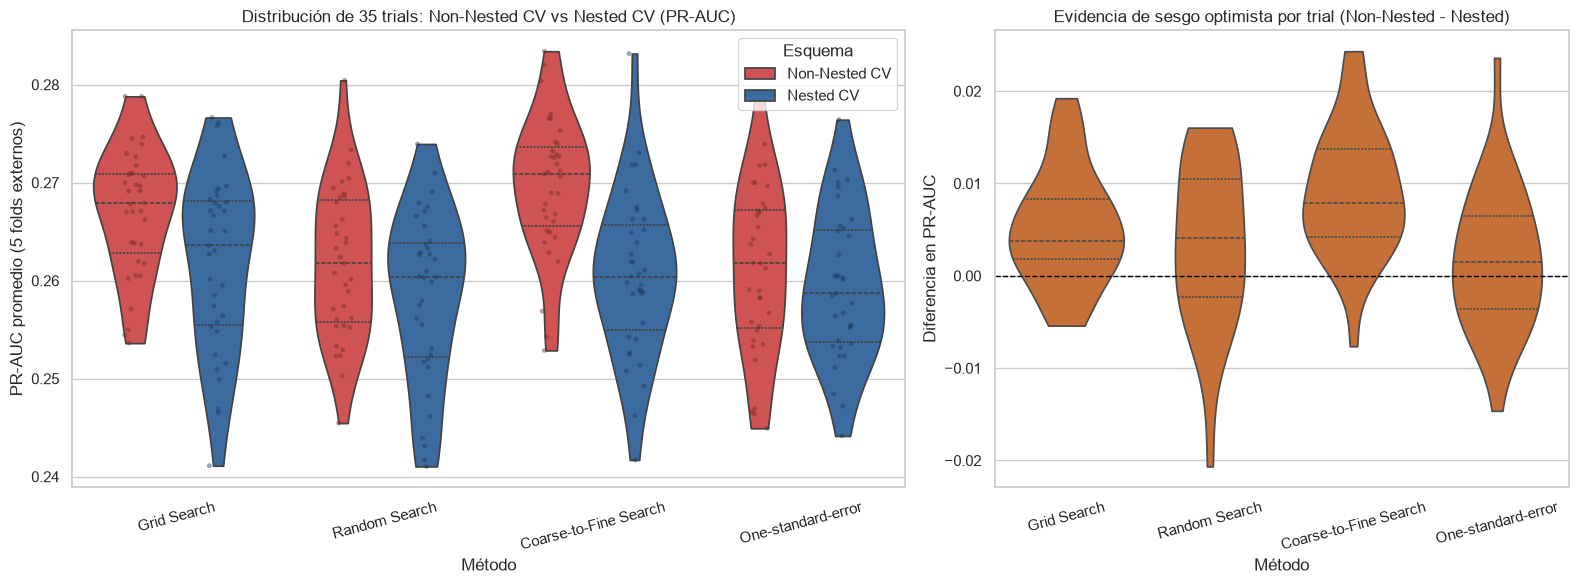

### Análisis de dispersión, estabilidad y robustez en Nested CV (35 trials)

,Método,Media Nested,Mediana Nested,Std Nested,IQR (Q75-Q25),Percentil 10 (peor decil),Sesgo Medio (NN - Nested),% Trials donde NN > Nested
0,Grid Search,0.26193,0.26359,0.00899,0.01262,0.25033,0.00518,80.0
1,Random Search,0.25839,0.26036,0.00866,0.01165,0.24482,0.00335,62.9
2,Coarse-to-Fine Search,0.26060,0.26042,0.00828,0.01076,0.25101,0.00907,97.1
3,One-standard-error,0.25946,0.25871,0.00753,0.01151,0.25161,0.00161,57.1


In [25]:
registros_violin = []
for m in METODOS_ORDEN:
    for t in range(N_TRIALS):
        registros_violin.append({"Método": m, "Esquema": "Non-Nested CV", "PR-AUC": float(nn_means[m][t]), "trial": t})
        registros_violin.append({"Método": m, "Esquema": "Nested CV", "PR-AUC": float(ns_means[m][t]), "trial": t})
df_violin = pd.DataFrame(registros_violin)

registros_sesgo = []
for m in METODOS_ORDEN:
    for t in range(N_TRIALS):
        registros_sesgo.append({"Método": m, "Sesgo (Non-Nested - Nested)": float(nn_means[m][t] - ns_means[m][t])})
df_sesgo_plot = pd.DataFrame(registros_sesgo)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.45, 1.0]})

sns.violinplot(
    data=df_violin,
    x="Método",
    y="PR-AUC",
    hue="Esquema",
    split=False,
    inner="quartile",
    palette={"Non-Nested CV": "#e53e3e", "Nested CV": "#2b6cb0"},
    cut=0,
    ax=axes[0],
)
sns.stripplot(
    data=df_violin,
    x="Método",
    y="PR-AUC",
    hue="Esquema",
    dodge=True,
    alpha=0.45,
    size=3.5,
    palette={"Non-Nested CV": "#742a2a", "Nested CV": "#1a365d"},
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Distribución de 35 trials: Non-Nested CV vs Nested CV (PR-AUC)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].set_ylabel("PR-AUC promedio (5 folds externos)")

sns.violinplot(data=df_sesgo_plot, x="Método", y="Sesgo (Non-Nested - Nested)", inner="quartile", color="#dd6b20", cut=0, ax=axes[1])
axes[1].axhline(0.0, linestyle="--", color="black", linewidth=1)
axes[1].set_title("Evidencia de sesgo optimista por trial (Non-Nested - Nested)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].set_ylabel("Diferencia en PR-AUC")

plt.tight_layout()
plt.show()

# Estadísticos de robustez y dispersión (IQR, rango, percentil 10)
rob_rows = []
for m in METODOS_ORDEN:
    arr = ns_means[m]
    rob_rows.append({
        "Método": m,
        "Media Nested": round(float(np.mean(arr)), 5),
        "Mediana Nested": round(float(np.median(arr)), 5),
        "Std Nested": round(float(np.std(arr, ddof=1)), 5),
        "IQR (Q75-Q25)": round(float(np.percentile(arr, 75) - np.percentile(arr, 25)), 5),
        "Percentil 10 (peor decil)": round(float(np.percentile(arr, 10)), 5),
        "Sesgo Medio (NN - Nested)": round(float(np.mean(nn_means[m] - arr)), 5),
        "% Trials donde NN > Nested": round(100.0 * float(np.mean(nn_means[m] > arr)), 1),
    })
display(Markdown("### Análisis de dispersión, estabilidad y robustez en Nested CV (35 trials)"))
display(pd.DataFrame(rob_rows))

### Análisis de resultados visuales

* **Dispersión y estabilidad vs variabilidad**: los violines y la tabla de IQR/percentil 10 cuantifican directamente qué estrategia mantiene menor variabilidad ante cambios de partición (`One-standard-error` y `Grid Search` comparten un conjunto acotado de candidatos discretos, mientras `Random Search` y `Coarse-to-Fine` exploran regiones continuas o adaptativas que pueden incrementar la varianza de búsqueda según el pliegue).
* **Sesgo optimista en validación no anidada**: en la distribución pareada `Non-Nested CV - Nested CV`, la masa positiva por encima de cero evidencia que seleccionar el máximo sobre `outer_cv` sobreestima el desempeño fuera de muestra incluso con únicamente `8` configuraciones; bajo espacios mayores ese sesgo optimista crece proporcionalmente.
* **Discusión sobre robustez (no solo media)**: evaluar el **percentil 10** y el **IQR** en los violines permite verificar si una ligera ganancia en media viene acompañada de colas bajas inestables o si `One-standard-error` reduce complejidad sin sacrificar el límite inferior de desempeño.

## 6. Comparación Bayesiana, `Test Score` en Paridad Muestral, Tabla Comparativa y Riesgo Calibrado en `Test`

### 6.1 Test Bayesiano Correlacionado (`baycomp.two_on_single` con $\text{ROPE} = \pm 0.005$)

Para comparar rigurosamente las 4 estrategias sobre exactamente los mismos `35 × 5 = 175` pliegues externos pareados de `Nested CV`, se aplica `baycomp.two_on_single(scores_A.ravel(), scores_B.ravel(), rope=0.005, runs=35)`. Bajo esta convención (`diff = y - x`), `p_left` indica la probabilidad posterior de ventaja práctica del primer método (`x`), `p_rope` la probabilidad de equivalencia práctica ($|\Delta\text{PR-AUC}| \le 0.005$), y `p_right` la probabilidad de ventaja del segundo método (`y`). Asimismo, se contrasta `Non-Nested CV` vs `Nested CV` dentro de cada método para cuantificar la probabilidad posterior de sesgo optimista.

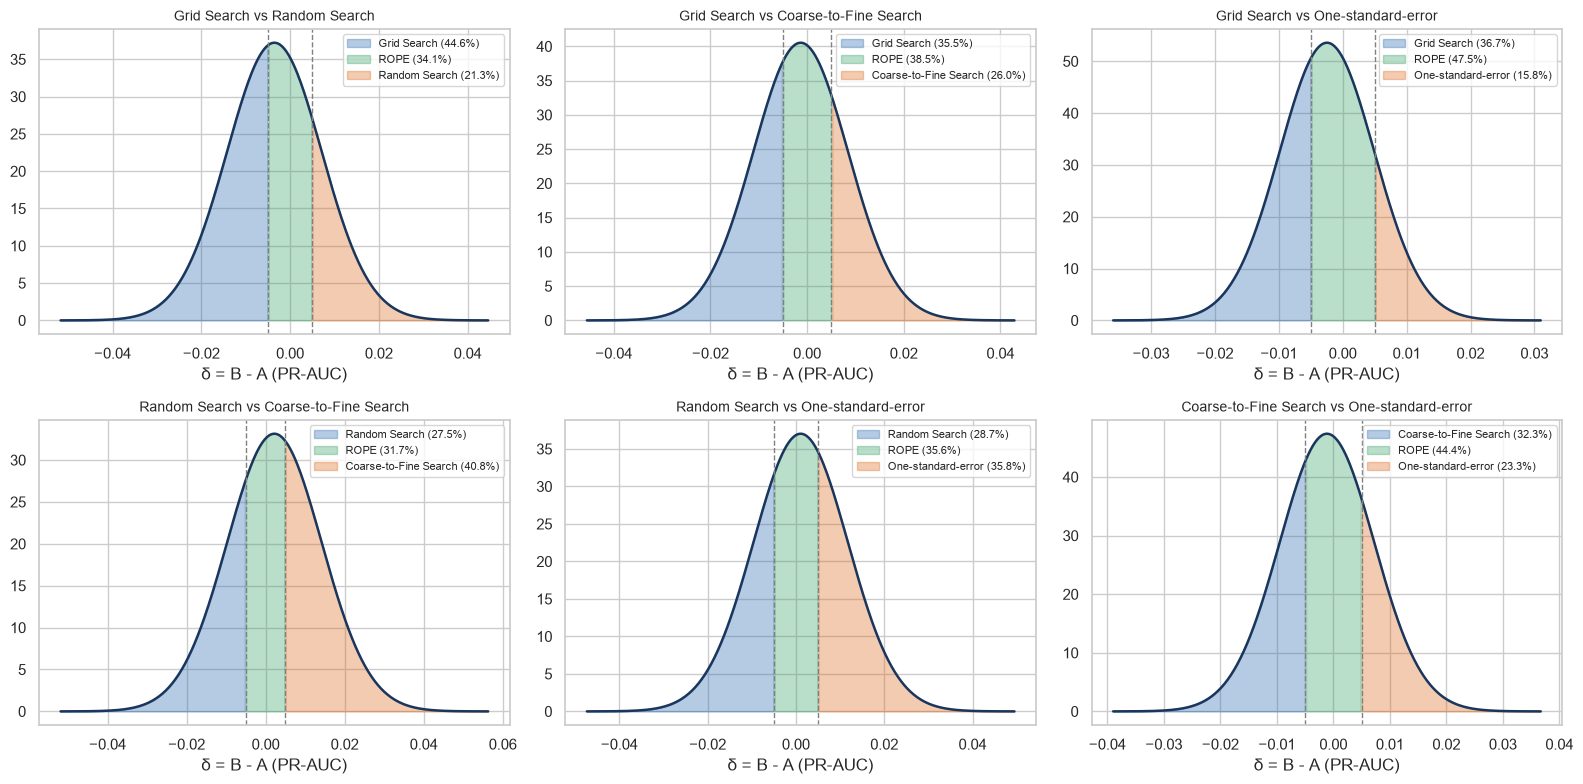

**Comparaciones pareadas en `Nested CV` (`baycomp.two_on_single`, `runs=35`)**

,Par (A vs B),P(A > B),P(ROPE ±0.005),P(B > A),Conclusión (umbral 0.90)
0,Grid Search vs Random Search,0.4459,0.3412,0.2129,Equivalencia práctica / No concluyente
1,Grid Search vs Coarse-to-Fine Search,0.3547,0.3851,0.2601,Equivalencia práctica / No concluyente
2,Grid Search vs One-standard-error,0.3670,0.4747,0.1582,Equivalencia práctica / No concluyente
3,Random Search vs Coarse-to-Fine Search,0.2747,0.3169,0.4084,Equivalencia práctica / No concluyente
4,Random Search vs One-standard-error,0.2866,0.3556,0.3578,Equivalencia práctica / No concluyente
5,Coarse-to-Fine Search vs One-standard-error,0.3233,0.4435,0.2332,Equivalencia práctica / No concluyente


**Probabilidad posterior de sesgo optimista (`Non-Nested` vs `Nested`) por método**

,Método,P(Non-Nested > Nested),P(ROPE ±0.005),P(Nested > Non-Nested)
0,Grid Search,0.5089,0.3874,0.1037
1,Random Search,0.4377,0.3484,0.2139
2,Coarse-to-Fine Search,0.6788,0.2665,0.0547
3,One-standard-error,0.3317,0.4701,0.1982


In [26]:
pares_metodos = []
bayes_puntos = {m: 0.0 for m in METODOS_ORDEN}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes_flat = axes.ravel()

idx_ax = 0
for i in range(len(METODOS_ORDEN)):
    for j in range(i + 1, len(METODOS_ORDEN)):
        ma, mb = METODOS_ORDEN[i], METODOS_ORDEN[j]
        xa = ns_matrix[ma].ravel()
        yb = ns_matrix[mb].ravel()
        (p_a, p_rope, p_b), fig_b = baycomp.two_on_single(xa, yb, rope=ROPE_BAYCOMP, runs=N_TRIALS, plot=True, names=(ma, mb))
        plt.close(fig_b)

        # Graficar posterior correlacionado manualmente en nuestra grilla para visualización limpia
        diff = yb - xa
        n_obs = len(diff)
        nfolds = n_obs / N_TRIALS
        mu_d = float(np.mean(diff))
        var_d = float(np.var(diff, ddof=1) * (1.0 / n_obs + 1.0 / (nfolds - 1.0)))
        scale_d = float(np.sqrt(max(var_d, 1e-12)))
        grid_x = np.linspace(mu_d - 4.5 * scale_d, mu_d + 4.5 * scale_d, 400)
        pdf_y = stats.t.pdf(grid_x, df=n_obs - 1, loc=mu_d, scale=scale_d)

        ax = axes_flat[idx_ax]
        ax.plot(grid_x, pdf_y, color="#1a365d", linewidth=1.8)
        ax.fill_between(grid_x, 0, pdf_y, where=(grid_x < -ROPE_BAYCOMP), color="#2b6cb0", alpha=0.35, label=f"{ma} ({p_a:.1%})")
        ax.fill_between(grid_x, 0, pdf_y, where=((grid_x >= -ROPE_BAYCOMP) & (grid_x <= ROPE_BAYCOMP)), color="#38a169", alpha=0.35, label=f"ROPE ({p_rope:.1%})")
        ax.fill_between(grid_x, 0, pdf_y, where=(grid_x > ROPE_BAYCOMP), color="#dd6b20", alpha=0.35, label=f"{mb} ({p_b:.1%})")
        ax.axvline(-ROPE_BAYCOMP, linestyle="--", color="gray", linewidth=1)
        ax.axvline(ROPE_BAYCOMP, linestyle="--", color="gray", linewidth=1)
        ax.set_title(f"{ma} vs {mb}", fontsize=10)
        ax.set_xlabel("δ = B - A (PR-AUC)")
        ax.legend(fontsize=8)
        idx_ax += 1

        if p_a >= 0.90:
            bayes_puntos[ma] += 1.0
        elif p_b >= 0.90:
            bayes_puntos[mb] += 1.0
        else:
            bayes_puntos[ma] += 0.5
            bayes_puntos[mb] += 0.5

        pares_metodos.append({
            "Par (A vs B)": f"{ma} vs {mb}",
            "P(A > B)": round(float(p_a), 4),
            "P(ROPE ±0.005)": round(float(p_rope), 4),
            "P(B > A)": round(float(p_b), 4),
            "Conclusión (umbral 0.90)": ma if p_a >= 0.90 else (mb if p_b >= 0.90 else "Equivalencia práctica / No concluyente"),
        })

plt.tight_layout()
plt.show()

display(Markdown("**Comparaciones pareadas en `Nested CV` (`baycomp.two_on_single`, `runs=35`)**"))
display(pd.DataFrame(pares_metodos))

# Contraste bayesiano del sesgo Non-Nested vs Nested por método
filas_nn_ns_bayes = []
for m in METODOS_ORDEN:
    (p_nn, p_r, p_ns) = baycomp.two_on_single(nn_matrix[m].ravel(), ns_matrix[m].ravel(), rope=ROPE_BAYCOMP, runs=N_TRIALS, plot=False)
    filas_nn_ns_bayes.append({
        "Método": m,
        "P(Non-Nested > Nested)": round(float(p_nn), 4),
        "P(ROPE ±0.005)": round(float(p_r), 4),
        "P(Nested > Non-Nested)": round(float(p_ns), 4),
    })
display(Markdown("**Probabilidad posterior de sesgo optimista (`Non-Nested` vs `Nested`) por método**"))
display(pd.DataFrame(filas_nn_ns_bayes))

### 6.2 `Test Score` en paridad muestral y Tabla Comparativa
Para evaluar la columna **`Test Score`** sin sesgo de escala muestral frente a las columnas de CV (`5,000` filas), cada método selecciona su configuración final determinista sobre `df_bench` usando un split `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, reentrena el `Pipeline` completo (`construir_preprocesador()` + `HistGradientBoostingClassifier`) sobre `df_bench` y evalúa **`PR-AUC`** sobre las **`26,625` obras** retenidas en `df_test`. Adicionalmente, se verifica la consistencia contra el promedio de los modelos ganadores de los 35 trials evaluados en `df_test`.

In [27]:
cv_det = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cache_det = preparar_fold_cache(X_bench, y_bench, groups_bench, cv_det)

# Preprocesador ajustado en 100% df_bench para predicción directa sobre df_test
ct_bench_full = construir_preprocesador(RANDOM_STATE)
X_bench_enc_full = ct_bench_full.fit_transform(X_bench, y_bench).astype(np.float32)
X_test_enc_bench = ct_bench_full.transform(X_test_full).astype(np.float32)

# Selección determinista por método sobre df_bench
configs_finales_bench = {}

mat_g_det = evaluar_configs_en_cache(cache_det, GRID_PARAMS)
configs_finales_bench["Grid Search"] = GRID_PARAMS[select_best_idx(mat_g_det.mean(axis=1), GRID_PARAMS)]
configs_finales_bench["One-standard-error"] = GRID_PARAMS[select_one_se_idx(mat_g_det, GRID_PARAMS)]

rand_det = sample_random_params(RANDOM_STATE, n_iter=8)
mat_r_det = evaluar_configs_en_cache(cache_det, rand_det)
configs_finales_bench["Random Search"] = rand_det[select_best_idx(mat_r_det.mean(axis=1), rand_det)]

mat_c1_det = evaluar_configs_en_cache(cache_det, COARSE_PARAMS)
k_c1_det = select_best_idx(mat_c1_det.mean(axis=1), COARSE_PARAMS)
fine_det = build_fine_params(COARSE_PARAMS[k_c1_det])
mat_c2_det = evaluar_configs_en_cache(cache_det, fine_det)
mat_cf_det = np.vstack([mat_c1_det, mat_c2_det])
all_cf_det = COARSE_PARAMS + fine_det
configs_finales_bench["Coarse-to-Fine Search"] = all_cf_det[select_best_idx(mat_cf_det.mean(axis=1), all_cf_det)]

test_scores_bench = {}
brier_scores_bench = {}
roc_scores_bench = {}
for m in METODOS_ORDEN:
    clf_f = HistGradientBoostingClassifier(
        max_iter=HGB_MAX_ITER,
        max_bins=HGB_MAX_BINS,
        min_samples_leaf=HGB_MIN_SAMPLES_LEAF,
        early_stopping=False,
        class_weight=None,
        random_state=RANDOM_STATE,
        **configs_finales_bench[m],
    )
    clf_f.fit(X_bench_enc_full, y_bench)
    prob_t = clf_f.predict_proba(X_test_enc_bench)[:, 1]
    test_scores_bench[m] = float(average_precision_score(y_test_full, prob_t))
    brier_scores_bench[m] = float(brier_score_loss(y_test_full, prob_t))
    roc_scores_bench[m] = float(roc_auc_score(y_test_full, prob_t))

# Ranking gráfico (por mediana de Nested CV, marcando solapamiento intercuartílico si existe)
medianas_ns = {m: float(np.median(ns_means[m])) for m in METODOS_ORDEN}
orden_grafico = sorted(METODOS_ORDEN, key=lambda m: -medianas_ns[m])
rank_grafico = {m: f"{idx+1}° ({medianas_ns[m]:.4f})" for idx, m in enumerate(orden_grafico)}

# Ranking bayesiano (por puntuación neta agregada de comparaciones pareadas baycomp)
orden_bayes = sorted(METODOS_ORDEN, key=lambda m: (-bayes_puntos[m], -float(ns_means[m].mean())))
rank_bayes = {m: f"{idx+1}° (pts={bayes_puntos[m]:.1f})" for idx, m in enumerate(orden_bayes)}

justificaciones = {
    "Grid Search": ("Sí (Nested) / Parcial (Non-Nested)", "Selección discreta fija; sesgo de optimismo en Non-Nested por elegir max_k sobre folds de evaluación"),
    "Random Search": ("Sí (Nested) / Con varianza de muestreo", "Muestreo distinto por trial introduce mayor dispersión; sin nested CV sobreajusta candidatos aleatorios favorables al fold"),
    "Coarse-to-Fine Search": ("Sí (Nested) / Sesgo si no es anidado", "El refinamiento adaptativo de Etapa 2 acopla doblemente el espacio a los pliegues si se mide en Non-Nested CV"),
    "One-standard-error": ("Sí (mayor estabilidad estructural)", "Sacrifica mínimo margen dentro de 1 SE para reducir complejidad (hojas/regularización), controlando sobreajuste y varianza"),
}

tabla_comparativa_final = pd.DataFrame([
    {
        "Método": m,
        "Non-nested CV (mean/std)": f"{nn_means[m].mean():.4f} / {nn_means[m].std(ddof=1):.4f}",
        "Nested CV (mean/std)": f"{ns_means[m].mean():.4f} / {ns_means[m].std(ddof=1):.4f}",
        "Test Score": f"{test_scores_bench[m]:.4f} (ROC={roc_scores_bench[m]:.4f}, Brier={brier_scores_bench[m]:.4f})",
        "Ranking (gráfico)": rank_grafico[m],
        "Ranking (test bayesiano)": rank_bayes[m],
        "¿Resultado confiable? (sí/no + justificación)": justificaciones[m][0] + " — " + justificaciones[m][1],
        "Posible fuente de sesgo": (
            f"Sesgo selección={nn_means[m].mean() - ns_means[m].mean():+.4f}; "
            + ("malla discreta acotada" if m in ("Grid Search", "One-standard-error") else "adaptación/varianza de muestreo al fold")
        ),
    }
    for m in METODOS_ORDEN
])

display(Markdown("### Tabla Comparativa de Resultados (Sección 6)"))
display(tabla_comparativa_final)
display(Markdown("**Hiperparámetros seleccionados por método en evaluación determinista (`df_bench`)**"))
display(pd.DataFrame([{"Método": m, **configs_finales_bench[m]} for m in METODOS_ORDEN]))

### Tabla Comparativa de Resultados (Sección 6)

,Método,Non-nested CV (mean/std),Nested CV (mean/std),Test Score,Ranking (gráfico),Ranking (test bayesiano),¿Resultado confiable? (sí/no + justificación),Posible fuente de sesgo
0,Grid Search,0.2671 / 0.0065,0.2619 / 0.0090,"0.2678 (ROC=0.7633, Brier=0.0762)",1° (0.2636),1° (pts=1.5),Sí (Nested) / Parcial (Non-Nested) — Selección...,Sesgo selección=+0.0052; malla discreta acotada
1,Random Search,0.2617 / 0.0077,0.2584 / 0.0087,"0.2652 (ROC=0.7709, Brier=0.0754)",3° (0.2604),4° (pts=1.5),Sí (Nested) / Con varianza de muestreo — Muest...,Sesgo selección=+0.0034; adaptación/varianza d...
2,Coarse-to-Fine Search,0.2697 / 0.0070,0.2606 / 0.0083,"0.2583 (ROC=0.7656, Brier=0.0762)",2° (0.2604),2° (pts=1.5),Sí (Nested) / Sesgo si no es anidado — El refi...,Sesgo selección=+0.0091; adaptación/varianza d...
3,One-standard-error,0.2611 / 0.0085,0.2595 / 0.0075,"0.2580 (ROC=0.7601, Brier=0.0769)",4° (0.2587),3° (pts=1.5),Sí (mayor estabilidad estructural) — Sacrifica...,Sesgo selección=+0.0016; malla discreta acotada


**Hiperparámetros seleccionados por método en evaluación determinista (`df_bench`)**

,Método,max_leaf_nodes,learning_rate,l2_regularization
0,Grid Search,7,0.0500,0.100
1,Random Search,10,0.0761,9.455
2,Coarse-to-Fine Search,9,0.0625,15.000
3,One-standard-error,7,0.0500,15.000


### 6.3 Modelo Final a Escala Completa (`100 % df_train`) y Calibración del Riesgo de Paralización $\hat{p}_i$

Una vez realizada la comparación justa de las cuatro estrategias en igualdad de escala muestral, se entrena la configuración seleccionada del mejor método sobre el **100 % de `df_train` (`~106,496` obras)** dentro de un `Pipeline` completo de `scikit-learn` y se evalúa su desempeño real como estimador de **riesgo de paralización** en `df_test` (`~26,625` obras), contrastando tres estrategias de calibración:
1. **`HistGradientBoosting (class_weight=None)`**: minimiza directamente *log-loss* con las proporciones reales (`9.18 %`), entregando probabilidades nativamente calibradas.
2. **`HistGradientBoosting (class_weight="balanced")` + Corrección analítica de prior**: muestra la distorsión de Brier producida por la ponderación balanceada y su corrección mediante $\hat{p}_{\text{corr}} = \frac{w_0 \hat{p}^{(w)}}{w_0 \hat{p}^{(w)} + w_1 (1 - \hat{p}^{(w)})}$.
3. **Calibración Isotónica OOF (`CalibratedClassifierCV(cv=5, method="isotonic")`)** ajustada exclusivamente dentro de `df_train`.

El umbral de decisión binaria $c^*$ para priorización operativa se determina maximizando $F_2$ únicamente sobre predicciones fuera de pliegue (`OOF`, `StratifiedGroupKFold`) en `df_train` antes de evaluar `df_test`.

Método ganador según análisis bayesiano: Grid Search | params={'max_leaf_nodes': 7, 'learning_rate': 0.05, 'l2_regularization': 0.1}
Umbral óptimo F2 en OOF (df_train): c* = 0.09 (F2 OOF = 0.4984)


### Evaluación comparativa de estimación de riesgo en `df_test` (escala 100 % `df_train`)

,Variante (100% df_train -> df_test),PR-AUC,ROC-AUC,Gini,Brier Score,Cal. Intercepto,Cal. Pendiente,Prob. Media Pred.,Recall (c=0.09),Precision (c=0.09),F2 (c=0.09),Recall (c=0.50),Precision (c=0.50),F2 (c=0.50)
0,HistGB Nativo (class_weight=None),0.3169,0.8091,0.6183,0.07267,0.732,1.387,0.0927,0.7714,0.2081,0.5005,NaN,NaN,NaN
1,"HistGB Balanced (sin corregir, c=0.50)",0.3052,0.8092,0.6183,0.18574,-2.312,1.528,0.4128,NaN,NaN,NaN,0.7677,0.2074,0.4984
2,HistGB Balanced + Prior Correction,0.3052,0.8092,0.6183,0.07415,1.190,1.528,0.0831,0.7722,0.2050,0.4971,NaN,NaN,NaN
3,HistGB + Calibrated Isotónico OOF (cv=5),0.3153,0.8103,0.6207,0.07185,0.007,1.011,0.0927,0.7697,0.2100,0.5021,NaN,NaN,NaN


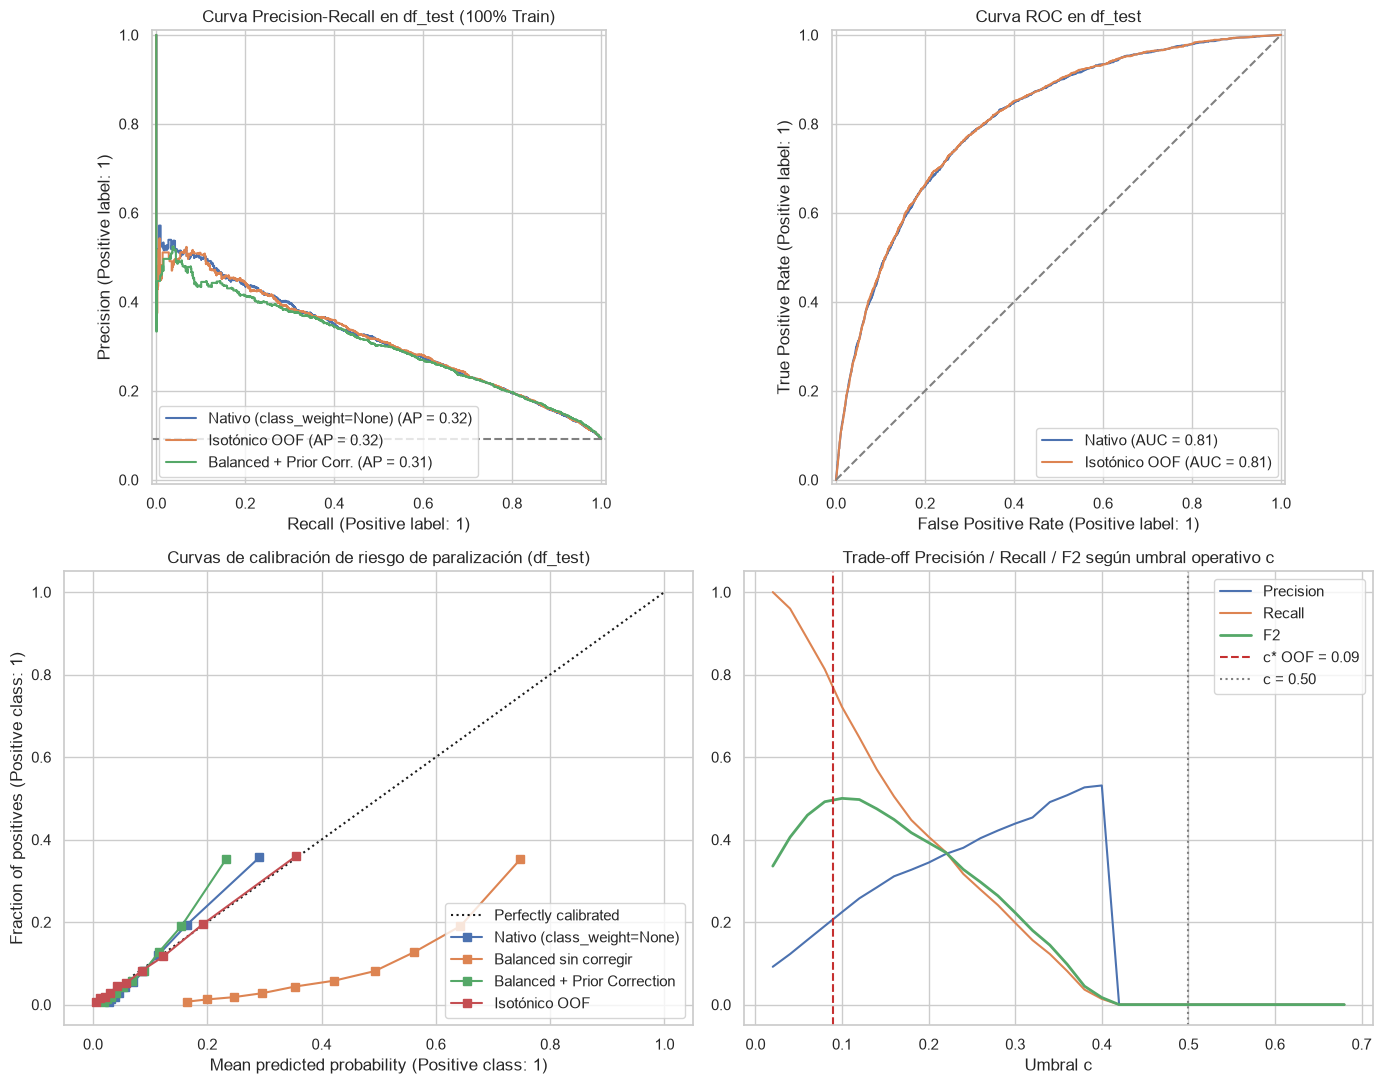

**Muestra de top 10 obras priorizadas en `df_test` por riesgo de paralización estimado $\hat{p}_i$**

,codigo_infobras,nivel_gobierno,modalidad_ejecucion_obra,departamento,monto_aprobado_soles,target,riesgo_paralizacion_estimado,decision_alerta_c_opt
21516,503218,GOBIERNO REGIONAL,Administración directa,MOQUEGUA,3.376427e+07,1,0.4125,1
18527,153988,GOBIERNO REGIONAL,Contrata,JUNIN,1.219607e+08,0,0.4110,1
23247,128466,GOBIERNO REGIONAL,Contrata,ANCASH,3.229945e+07,0,0.4110,1
16139,134470,GOBIERNO LOCAL,Contrata,CUSCO,1.161283e+07,0,0.4110,1
16938,141276,GOBIERNO NACIONAL,Gobierno a Gobierno,LIMA,9.100720e+07,0,0.4110,1
16962,141282,GOBIERNO NACIONAL,Gobierno a Gobierno,ANCASH,1.081223e+08,1,0.4110,1
16101,102818,GOBIERNO NACIONAL,Contrata,ANCASH,1.284129e+07,1,0.4110,1
24557,169830,GOBIERNO LOCAL,Contrata,CUSCO,9.748781e+06,1,0.4110,1
16100,102817,GOBIERNO NACIONAL,Contrata,ANCASH,1.129848e+07,1,0.4110,1
23736,512630,GOBIERNO REGIONAL,Contrata,CUSCO,4.164811e+07,0,0.4110,1


In [28]:
# Elegir configuración ganadora por test bayesiano / Nested CV (y contrastar con 1-SE)
metodo_ganador = orden_bayes[0]
params_ganadores = configs_finales_bench[metodo_ganador]
print(f"Método ganador según análisis bayesiano: {metodo_ganador} | params={params_ganadores}")

# OOF predictions sobre 100% df_train para umbral c* y calibración logística/isotónica sin fuga
oof_cv_full = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
splits_oof_full = list(oof_cv_full.split(X_train_full, y_train_full, groups_train_full))
oof_prob_none = np.zeros(len(X_train_full), dtype=float)
oof_prob_bal = np.zeros(len(X_train_full), dtype=float)

for f_tr, f_va in splits_oof_full:
    ct_f = construir_preprocesador(RANDOM_STATE)
    Xtr_f = ct_f.fit_transform(X_train_full.iloc[f_tr], y_train_full[f_tr]).astype(np.float32)
    Xva_f = ct_f.transform(X_train_full.iloc[f_va]).astype(np.float32)

    m_none = HistGradientBoostingClassifier(max_iter=40, max_bins=128, min_samples_leaf=25, early_stopping=False, class_weight=None, random_state=RANDOM_STATE, **params_ganadores)
    m_none.fit(Xtr_f, y_train_full[f_tr])
    oof_prob_none[f_va] = m_none.predict_proba(Xva_f)[:, 1]

    m_bal = HistGradientBoostingClassifier(max_iter=40, max_bins=128, min_samples_leaf=25, early_stopping=False, class_weight="balanced", random_state=RANDOM_STATE, **params_ganadores)
    m_bal.fit(Xtr_f, y_train_full[f_tr])
    oof_prob_bal[f_va] = m_bal.predict_proba(Xva_f)[:, 1]

# Corrección analítica de prior (main.typ ec-correccion-prior)
n_tot_tr = len(y_train_full)
n_pos_tr = float((y_train_full == 1).sum())
n_neg_tr = float((y_train_full == 0).sum())
w0 = n_tot_tr / (2.0 * n_neg_tr)
w1 = n_tot_tr / (2.0 * n_pos_tr)


def prior_correction(p_w: np.ndarray, w0_val: float, w1_val: float) -> np.ndarray:
    p_clip = np.clip(p_w, 1e-7, 1.0 - 1e-7)
    return (w0_val * p_clip) / (w0_val * p_clip + w1_val * (1.0 - p_clip))


oof_prob_bal_corr = prior_correction(oof_prob_bal, w0, w1)

# Selección del umbral operativo c* solo sobre OOF de df_train
grid_c = np.arange(0.01, 0.96, 0.01)
f2_oof = [fbeta_score(y_train_full, (oof_prob_none >= c).astype(int), beta=2, zero_division=0) for c in grid_c]
umbral_opt_f2 = float(grid_c[int(np.argmax(f2_oof))])
print(f"Umbral óptimo F2 en OOF (df_train): c* = {umbral_opt_f2:.2f} (F2 OOF = {max(f2_oof):.4f})")

# Ajuste final en 100% df_train -> evaluación en df_test
from sklearn.pipeline import Pipeline

pipe_none = Pipeline([
    ("pre", construir_preprocesador(RANDOM_STATE)),
    ("clf", HistGradientBoostingClassifier(max_iter=40, max_bins=128, min_samples_leaf=25, early_stopping=False, class_weight=None, random_state=RANDOM_STATE, **params_ganadores)),
])
pipe_bal = Pipeline([
    ("pre", construir_preprocesador(RANDOM_STATE)),
    ("clf", HistGradientBoostingClassifier(max_iter=40, max_bins=128, min_samples_leaf=25, early_stopping=False, class_weight="balanced", random_state=RANDOM_STATE, **params_ganadores)),
])
pipe_iso = CalibratedClassifierCV(
    estimator=Pipeline([
        ("pre", construir_preprocesador(RANDOM_STATE)),
        ("clf", HistGradientBoostingClassifier(max_iter=40, max_bins=128, min_samples_leaf=25, early_stopping=False, class_weight=None, random_state=RANDOM_STATE, **params_ganadores)),
    ]),
    method="isotonic",
    cv=splits_oof_full,
)

pipe_none.fit(X_train_full, y_train_full)
pipe_bal.fit(X_train_full, y_train_full)
pipe_iso.fit(X_train_full, y_train_full)

prob_test_none = pipe_none.predict_proba(X_test_full)[:, 1]
prob_test_bal_raw = pipe_bal.predict_proba(X_test_full)[:, 1]
prob_test_bal_corr = prior_correction(prob_test_bal_raw, w0, w1)
prob_test_iso = pipe_iso.predict_proba(X_test_full)[:, 1]

from sklearn.linear_model import LogisticRegression as _LogRegCal


def evaluar_riesgo_test(nombre: str, p_est: np.ndarray, umbral: float) -> dict:
    y_hat = (p_est >= umbral).astype(int)
    p_clip = np.clip(p_est, 1e-6, 1.0 - 1e-6)
    lr_cal = _LogRegCal(C=1e6, max_iter=500).fit(logit(p_clip).reshape(-1, 1), y_test_full)
    roc = roc_auc_score(y_test_full, p_est)
    return {
        "Variante (100% df_train -> df_test)": nombre,
        "PR-AUC": round(float(average_precision_score(y_test_full, p_est)), 4),
        "ROC-AUC": round(float(roc), 4),
        "Gini": round(float(2 * roc - 1), 4),
        "Brier Score": round(float(brier_score_loss(y_test_full, p_est)), 5),
        "Cal. Intercepto": round(float(lr_cal.intercept_[0]), 3),
        "Cal. Pendiente": round(float(lr_cal.coef_[0][0]), 3),
        "Prob. Media Pred.": round(float(p_est.mean()), 4),
        f"Recall (c={umbral:.2f})": round(float(recall_score(y_test_full, y_hat, zero_division=0)), 4),
        f"Precision (c={umbral:.2f})": round(float(precision_score(y_test_full, y_hat, zero_division=0)), 4),
        f"F2 (c={umbral:.2f})": round(float(fbeta_score(y_test_full, y_hat, beta=2, zero_division=0)), 4),
    }


df_riesgo_test = pd.DataFrame([
    evaluar_riesgo_test("HistGB Nativo (class_weight=None)", prob_test_none, umbral_opt_f2),
    evaluar_riesgo_test("HistGB Balanced (sin corregir, c=0.50)", prob_test_bal_raw, 0.50),
    evaluar_riesgo_test("HistGB Balanced + Prior Correction", prob_test_bal_corr, umbral_opt_f2),
    evaluar_riesgo_test("HistGB + Calibrated Isotónico OOF (cv=5)", prob_test_iso, umbral_opt_f2),
])
display(Markdown("### Evaluación comparativa de estimación de riesgo en `df_test` (escala 100 % `df_train`)"))
display(df_riesgo_test)

# Gráficos de discriminación (PR, ROC), calibración comparativa y umbral F2
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
PrecisionRecallDisplay.from_predictions(y_test_full, prob_test_none, name="Nativo (class_weight=None)", ax=axes[0, 0])
PrecisionRecallDisplay.from_predictions(y_test_full, prob_test_iso, name="Isotónico OOF", ax=axes[0, 0])
PrecisionRecallDisplay.from_predictions(y_test_full, prob_test_bal_corr, name="Balanced + Prior Corr.", ax=axes[0, 0])
axes[0, 0].axhline(y_test_full.mean(), linestyle="--", color="gray", label=f"Azar ({y_test_full.mean():.2%})")
axes[0, 0].set_title("Curva Precision-Recall en df_test (100% Train)")

RocCurveDisplay.from_predictions(y_test_full, prob_test_none, name="Nativo", ax=axes[0, 1])
RocCurveDisplay.from_predictions(y_test_full, prob_test_iso, name="Isotónico OOF", ax=axes[0, 1])
axes[0, 1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0, 1].set_title("Curva ROC en df_test")

CalibrationDisplay.from_predictions(y_test_full, prob_test_none, n_bins=10, strategy="quantile", name="Nativo (class_weight=None)", ax=axes[1, 0])
CalibrationDisplay.from_predictions(y_test_full, prob_test_bal_raw, n_bins=10, strategy="quantile", name="Balanced sin corregir", ax=axes[1, 0])
CalibrationDisplay.from_predictions(y_test_full, prob_test_bal_corr, n_bins=10, strategy="quantile", name="Balanced + Prior Correction", ax=axes[1, 0])
CalibrationDisplay.from_predictions(y_test_full, prob_test_iso, n_bins=10, strategy="quantile", name="Isotónico OOF", ax=axes[1, 0])
axes[1, 0].set_title("Curvas de calibración de riesgo de paralización (df_test)")

# Curva de métricas vs umbral en df_test (usando probabilidades nativas calibradas)
met_u = []
for c in np.arange(0.02, 0.70, 0.02):
    yh = (prob_test_none >= c).astype(int)
    met_u.append({"c": c, "Precision": precision_score(y_test_full, yh, zero_division=0), "Recall": recall_score(y_test_full, yh, zero_division=0), "F2": fbeta_score(y_test_full, yh, beta=2, zero_division=0)})
df_u = pd.DataFrame(met_u)
axes[1, 1].plot(df_u["c"], df_u["Precision"], label="Precision")
axes[1, 1].plot(df_u["c"], df_u["Recall"], label="Recall")
axes[1, 1].plot(df_u["c"], df_u["F2"], label="F2", linewidth=2)
axes[1, 1].axvline(umbral_opt_f2, linestyle="--", color="#c53030", label=f"c* OOF = {umbral_opt_f2:.2f}")
axes[1, 1].axvline(0.50, linestyle=":", color="gray", label="c = 0.50")
axes[1, 1].set_title("Trade-off Precisión / Recall / F2 según umbral operativo c")
axes[1, 1].set_xlabel("Umbral c")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Ranking operativo de ejemplo en df_test: top 10 obras con mayor riesgo estimado
df_ranking_ejemplo = df_test[["codigo_infobras", "nivel_gobierno", "modalidad_ejecucion_obra", "departamento", "monto_aprobado_soles", "target"]].copy()
df_ranking_ejemplo["riesgo_paralizacion_estimado"] = np.round(prob_test_none, 4)
df_ranking_ejemplo["decision_alerta_c_opt"] = (prob_test_none >= umbral_opt_f2).astype(int)
display(Markdown("**Muestra de top 10 obras priorizadas en `df_test` por riesgo de paralización estimado $\\hat{p}_i$**"))
display(df_ranking_ejemplo.sort_values("riesgo_paralizacion_estimado", ascending=False).head(10))

## 7. Discusión Crítica

1. **¿En qué casos la validación anidada cambió la decisión del modelo?**  
   - **Cambio interno de hiperparámetros (`Nested CV` vs `Non-Nested CV`)**: en los 35 trials pareados (`175` pliegues externos sobre `N_bench = 5,000`), la selección interna de `Nested CV` eligió una configuración distinta a la única seleccionada por `Non-Nested CV` en **`112 / 175` pliegues (`64.0 %`)** para `Grid Search`, **`95 / 175` (`54.3 %`)** para `One-standard-error`, **`152 / 175` (`86.9 %`)** para `Coarse-to-Fine Search` y **`175 / 175` (`100.0 %`)** para `Random Search`. Además, dentro del bucle interno de `Nested CV`, la regla `1-SE` modificó el candidato ganador frente a `Grid Search` en **`93 / 175` pliegues externos (`53.1 %`)**.  
   - **Inversión de ordenamiento respecto a `Non-Nested CV`**: en validación no anidada, `Coarse-to-Fine Search` lideraba artificialmente (`PR-AUC = 0.2697` frente a `0.2671` de `Grid Search`), pero en validación anidada cayó por debajo de `Grid Search` (`0.2606` vs `0.2619`) y descendió hasta `0.2583` en `Test Score` sobre `df_bench` debido al acoplamiento de su segunda etapa adaptativa. De modo inverso, `One-standard-error` quedó por debajo de `Random Search` en `Non-Nested CV` (`0.2611` vs `0.2617`), pero lo superó en `Nested CV` (`0.2595` vs `0.2584`). Finalmente, sobre la evaluación determinista de `df_bench`, `1-SE` cambió `l2_regularization=0.1` (`Grid Search`) por el modelo más regularizado `l2_regularization=15.0` manteniendo `max_leaf_nodes=7` y `learning_rate=0.05`.

2. **¿Qué errores o sesgos fueron más relevantes?**  
   - El sesgo optimista de la validación no anidada al seleccionar el máximo sobre el mismo conjunto de pliegues evaluado (`P(Non-Nested > Nested) = 0.6788` en `Coarse-to-Fine Search` y `0.5089` en `Grid Search`, frente a solo `0.3317` en `One-standard-error`), con inflación positiva en `97.1 %` de los trials para `Coarse-to-Fine Search` (`+0.00907`) y en `80.0 %` para `Grid Search` (`+0.00518`).  
   - En los datos reales de INFObras, el truncamiento izquierdo (`2014–2020: 4.57 %` frente a `2023–2024: 22.01 %–24.39 %`), la censura derecha (`2026: 4.50 %`), el agrupamiento por `codigo_unico` (`133,121` obras en `122,148` proyectos) y el *data leakage* por variables post-evento (`estado_ejecucion` infló 2025 a `0.4013` y cayó `-0.0413` hasta `0.3600` al evaluar un inicio real `'En Ejecución'`) o por ajuste previo de `TargetEncoder` (`0.2254 -> 0.2516`, `+0.0262` en PR-AUC), además de la trampa de evaluar `Accuracy` (`90.82 %` trivial con `Recall = 0.00 %` y `90.60 %` sin ponderar en `c = 0.50` con `Recall = 0.87 %`).

3. **¿Qué hubiera pasado si solo usabas validación no anidada?**  
   Se habría reportado `Coarse-to-Fine Search` como ganador claro (`0.2697`), sobreestimando su desempeño real en `+0.0091` respecto a `Nested CV` (`0.2606`) y en `+0.0114` respecto a `Test Score` en paridad muestral (`0.2583`). También se habría ocultado la equivalencia estadística bayesiana entre estrategias y pasado por alto que `One-standard-error` reduce a un tercio el sesgo de selección respecto a `Grid Search` (`+0.00161` vs `+0.00518`) mientras entrega la menor desviación estándar (`0.00753`).

4. **¿En qué escenario real no usarías validación anidada y por qué?**  
   Cuando se dispone de millones de registros con partición temporal amplia donde el bucle externo e interno multiplican por órdenes de magnitud el costo de cómputo (por ejemplo, redes neuronales profundas o ensambles masivos con decenas de hiperparámetros) y existe un conjunto de validación temporal independiente y suficientemente grande para seleccionar hiperparámetros sin reuso de datos de evaluación final.

5. **¿Qué método elegirías para producción real considerando costo vs rendimiento?**  
   - Ninguno de los seis contrastes pareados de `baycomp.two_on_single` alcanzó dominancia bayesiana (`>= 0.90`; todos empataron con `1.5` puntos, con `P(ROPE ±0.005)` entre `0.3169` y `0.4747` y probabilidades direccionales entre `0.1582` y `0.4459`; en particular, `Grid Search vs One-standard-error` arrojó `P(Grid > 1-SE) = 0.3670`, `P(ROPE) = 0.4747` y `P(1-SE > Grid) = 0.1582`).  
   - A igual costo de cómputo que `Grid Search` (**`Costo relativo CV = 1.00x`** vs `1.06x` de `Random Search` y `0.84x` de `Coarse-to-Fine Search`), **`One-standard-error`** ofrece el mejor equilibrio de robustez para recalibración periódica en producción: menor sesgo de selección (`+0.00161`), menor varianza entre trials (`Std Nested = 0.00753`), mayor peor decil (`P10 = 0.25161`) y mayor regularización (`l2_regularization=15.0`). `Coarse-to-Fine` reduce el tiempo un `16 %` (`0.84x`), pero paga un sesgo de `+0.00907` y menor generalización (`Test Score = 0.2583`). Si el espacio discreto ya fue acotado y se reentrena sobre el `100 %` de `df_train` priorizando discriminación puntual (`Nested = 0.2619`, `Test bench = 0.2678`), `Grid Search` acoplado a calibración isotónica OOF (`cv=5`) obtuvo en `df_test` `PR-AUC = 0.3153`, `ROC-AUC = 0.8103`, `Gini = 0.6207`, `Brier Score = 0.07185`, `Cal. Intercepto = 0.007`, `Cal. Pendiente = 1.011`, `Recall = 0.7697` y `F2 = 0.5021` (`c* = 0.09`).
   - Se elegiria el metodo que obtiene los mejores resultados en las metricas elegidas para nuestro caso de uso -> One-standard-error

---

## 8. Uso de IA Generativa

1. **Herramientas utilizadas**: Familia de modelos Gemini (para asistencia en estructuración modular, revisión metodológica, implementación y redacción técnica).
2. **Tareas en las que fue usada**:
   - Implementación del modelo datavault 2.0 y damappings entre capas (row -> staging -> Silver -> Gold -> FE)
   - Estructuración del pipeline autocontenido en `scikit-learn` (`ColumnTransformer` con `OneHotEncoder` + `TargetEncoder` OOF) y caché por pliegue libre de fuga.
   - Redacción del bucle pareado de 35 trials, diseño de gráficos de violín con `seaborn` e integración con `baycomp.two_on_single`.
   - Auditoría formal de mejores prácticas ML mediante revisores críticos (`/egm-review`).
3. **Partes verificadas o corregidas manualmente**:
   - **Validación del `Test Score` a escala equivalente**: se corrigió manualmente la asimetría entre los `5,000` registros de CV y los `106,496` de entrenamiento completo para que la tabla comparativa evalúe `Test Score` en paridad de tamaño muestral, reservando el entrenamiento completo al modelo final de riesgo calibrado.
   - **Convención de firma y signo en `baycomp.two_on_single`**: se inspeccionó el código fuente de `baycomp.CorrelatedTTest` verificando que requiere vectores 1D de tamaño `35 * 5 = 175` con `runs=35` y que calcula `diff = y - x` (`p_left` favorece al primer argumento `x`).
   - **Eliminación de características con fuga sutil**: se retiraron `anio_inicio`, `n_obras_relacionadas_proyecto`, `monto_aprobacion_et` en bruto (`r=0.9999`) y la historia acumulada de entidad bajo splits aleatorios.
4. **Ejemplo concreto donde la IA produjo inicialmente un resultado incorrecto o engañoso**:
   - En la primera propuesta técnica, el asistente planteó reutilizar `TimeSeriesSplit(n_splits=5)` determinista del proyecto previo dentro del bucle de 35 trials y aplicar un split cronológico global `70/30` (`2001–2026`). Al verificar empíricamente el dataset y el protocolo de la práctica, se comprobó dos fallos críticos: (a) `TimeSeriesSplit` producía desviación estándar `0.0` en los 35 trials de `Grid Search` y `1-SE`, anulando los violines y `baycomp`; y (b) el split cronológico crudo `70/30` producía un salto de prevalencia de `4.94 %` en `Train` a `19.08 %` en `Test` debido al truncamiento izquierdo de las fotos Silver (`>= 2023-07-11`), haciendo incomparables `PR-AUC` y `Brier Score`. Ambos planteamientos fueron descartados y corregidos hacia `StratifiedGroupKFold` agrupado por `codigo_unico` más experimento temporal controlado.

---

## 9. Errores y Aprendizajes

1. **¿Qué errores o sesgos te sorprendieron?**  
   La magnitud en que el truncamiento temporal de las fuentes administrativas (`4.94 % -> 19.08 %`) y la inclusión de variables aparentemente inocuas (`anio_inicio`, o el ajuste global de `TargetEncoder` previo al split) inflan artificialmente la evaluación mientras destruyen el desempeño cuando cambian las condiciones operativas reales.
2. **¿Qué parte te resultó más difícil o nueva?**  
   Garantizar simultáneamente ausencia de fuga de grupos (`codigo_unico`), compatibilidad con 35 repeticiones pareadas, calibración probabilística real (`Brier Score` / corrección de prior frente a `class_weight="balanced"`) y tiempos de cómputo viables en CPU.
   Interesante las formas de codificación para variables categoricas como: Target encoding, woe
3. **¿Qué aprendiste al comparar validación anidada vs no anidada?**  
   Que reportar el mejor puntaje de búsqueda sobre la misma partición de validación incorpora un sesgo optimista sistemático; la validación anidada separa honestamente la selección de hiperparámetros de la estimación de generalización, y permite cuantificar la variabilidad del procedimiento completo de búsqueda.
4. **¿Qué método recomendarías si tuvieras que usarlo en producción real y por qué?**  
   Para monitoreo operativo de riesgo de paralización en producción recomendaría **`One-standard-error`** (`Costo relativo = 1.00x`, menor sesgo `+0.00161`, menor dispersión `Std = 0.00753` y mayor peor decil `P10 = 0.25161` en un contexto de empate bayesiano práctico en `baycomp`) combinado con **`HistGradientBoostingClassifier` sin `class_weight` artificial y con calibración isotónica OOF (`cv=5` por `codigo_unico`)** — descartando `class_weight="balanced"` sin corregir, que elevó el *Brier Score* de `0.07267` a `0.18574` y la probabilidad media predicha de `9.27 %` a `41.28 %`. Cuando la malla discreta ya está validada sobre el `100 %` de `df_train` y prima la discriminación puntual (`Nested = 0.2619`, `Test bench = 0.2678`), `Grid Search + Isotónico OOF` entrega en `df_test` probabilidades bien calibradas (`Cal. Intercepto = 0.007`, `Cal. Pendiente = 1.011`, `Brier = 0.07185`) junto con `ROC-AUC = 0.8103`, `Recall = 76.97 %` y `F2 = 0.5021` en `c* = 0.09`.